## PREDICCION DE OCURRENCIA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv("C:/Users/herna/Downloads/accidents_2017_to_2023_english.csv")
df.head()

,inverse_data,week_day,hour,state,road_id,km,city,cause_of_accident,type_of_accident,victims_condition,weather_timestamp,road_direction,wheather_condition,road_type,road_delineation,people,deaths,slightly_injured,severely_injured,uninjured,ignored,total_injured,vehicles_involved,latitude,longitude,regional,police_station
0,2017-01-01,sunday,01:45:00,RS,116.0,"34,9",VACARIA,Mechanical loss/defect of vehicle,Rear-end collision,With injured victims,Night,Decreasing,Clear sky,Simple,Straight,6,0,4,0,2,0,4,2,-28.50712,-50.94118,SPRF-RS,DEL05-RS
1,2017-01-01,sunday,01:00:00,PR,376.0,636,TIJUCAS DO SUL,Incompatible velocity,Run-off-road,With dead victims,Night,Increasing,Drizzle,Double,Curve,2,1,0,0,1,0,0,2,-25.75400,-49.12660,SPRF-PR,DEL01-PR
2,2017-01-01,sunday,04:40:00,BA,101.0,65,ENTRE RIOS,Driver was sleeping,Head-on collision,With dead victims,Sunrise,Decreasing,Cloudy,Simple,Curve,5,1,1,1,2,0,2,2,-11.96180,-38.09530,SPRF-BA,DEL01-BA
3,2017-01-01,sunday,06:30:00,PA,316.0,"72,5",CASTANHAL,Driver's lack of attention to conveyance,Side impact collision,With dead victims,Sunrise,Decreasing,Clear sky,Simple,Straight,4,1,0,0,3,0,0,3,-1.28998,-47.83483,SPRF-PA,DEL01-PA
4,2017-01-01,sunday,09:00:00,GO,20.0,"220,5",POSSE,Road's defect,Collision with fixed object,With injured victims,Day,Decreasing,Clear sky,Simple,Temporary Detour,3,0,2,1,0,0,3,1,-14.14221,-46.32259,SPRF-DF,DEL02-DF


In [3]:
# Estructura, tamaño del dataframe y nombre de las columnas

df.info()
df.shape
df.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 463152 entries, 0 to 463151
Data columns (total 27 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   inverse_data        463152 non-null  object 
 1   week_day            463152 non-null  object 
 2   hour                463152 non-null  object 
 3   state               463152 non-null  object 
 4   road_id             462162 non-null  float64
 5   km                  462162 non-null  object 
 6   city                463152 non-null  object 
 7   cause_of_accident   463152 non-null  object 
 8   type_of_accident    463152 non-null  object 
 9   victims_condition   463152 non-null  object 
 10  weather_timestamp   463152 non-null  object 
 11  road_direction      463152 non-null  object 
 12  wheather_condition  463152 non-null  object 
 13  road_type           463152 non-null  object 
 14  road_delineation    463152 non-null  object 
 15  people              463152 non-nul

Index(['inverse_data', 'week_day', 'hour', 'state', 'road_id', 'km', 'city',
       'cause_of_accident', 'type_of_accident', 'victims_condition',
       'weather_timestamp', 'road_direction', 'wheather_condition',
       'road_type', 'road_delineation', 'people', 'deaths', 'slightly_injured',
       'severely_injured', 'uninjured', 'ignored', 'total_injured',
       'vehicles_involved', 'latitude', 'longitude', 'regional',
       'police_station'],
      dtype='object')

In [4]:
# Tipos de Datos de las columnas
df.dtypes

inverse_data           object
week_day               object
hour                   object
state                  object
road_id               float64
km                     object
city                   object
cause_of_accident      object
type_of_accident       object
victims_condition      object
weather_timestamp      object
road_direction         object
wheather_condition     object
road_type              object
road_delineation       object
people                  int64
deaths                  int64
slightly_injured        int64
severely_injured        int64
uninjured               int64
ignored                 int64
total_injured           int64
vehicles_involved       int64
latitude              float64
longitude             float64
regional               object
police_station         object
dtype: object

In [5]:
# Cantidad de Nulos
df.isnull().sum().sort_values(ascending=False)

police_station        1310
road_id                990
km                     990
regional                10
people                   0
longitude                0
latitude                 0
vehicles_involved        0
total_injured            0
ignored                  0
uninjured                0
severely_injured         0
slightly_injured         0
deaths                   0
inverse_data             0
road_delineation         0
week_day                 0
wheather_condition       0
road_direction           0
weather_timestamp        0
victims_condition        0
type_of_accident         0
cause_of_accident        0
city                     0
state                    0
hour                     0
road_type                0
dtype: int64

In [6]:
# Cantidad de Duplicados
df.duplicated().sum()

np.int64(9)

In [7]:
# Estadisticas
df.describe()

,road_id,people,deaths,slightly_injured,severely_injured,uninjured,ignored,total_injured,vehicles_involved,latitude,longitude
count,462162.000000,463152.000000,463152.000000,463152.000000,463152.000000,463152.000000,463152.000000,463152.000000,463152.000000,4.631520e+05,4.631520e+05
mean,213.432900,2.362373,0.079235,0.835469,0.259530,1.044070,0.144069,1.094999,1.645725,-2.343287e+03,-8.924977e+03
std,130.757607,1.924801,0.332169,1.075275,0.602814,1.502419,0.438168,1.205351,0.731394,1.519113e+06,5.903043e+06
min,10.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,-1.033383e+09,-4.016764e+09
25%,101.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,-2.533123e+01,-5.030294e+01
50%,163.000000,2.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,2.000000,-2.042034e+01,-4.780831e+01
75%,324.000000,3.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,2.000000,-1.282657e+01,-4.264249e+01
max,498.000000,80.000000,21.000000,61.000000,31.000000,73.000000,54.000000,66.000000,23.000000,1.630000e+02,7.170000e+02


In [8]:
# Contidad de accidentes por carretera
print(df['road_id'].value_counts().head(20))

road_id
101.0    76540
116.0    68814
381.0    22978
40.0     21991
153.0    18271
364.0    15354
163.0    14847
277.0    13631
376.0    12876
262.0    12254
470.0    11369
282.0     9242
230.0     9038
316.0     8703
60.0      7539
70.0      6696
20.0      6033
476.0     5510
232.0     5495
280.0     5394
Name: count, dtype: int64


In [9]:
# ¿En qué estados pasa la BR-101?
df[df['road_id'] == 101]['state'].value_counts()

state
SC    27208
ES    12528
RJ    11123
PE     6981
BA     6002
RN     3753
PB     2575
SE     2376
AL     1877
SP     1097
RS     1020
Name: count, dtype: int64

In [10]:
# ¿Qué rango de kilómetros tiene?
df[df['road_id'] == 101]['km'].describe()

count     76540
unique     5877
top         207
freq        330
Name: km, dtype: object

In [20]:
# df[df['road_id'] == 101]['week_day'].nunique()

In [11]:
# ¿Cuántos días distintos tiene?
df[df['road_id'] == 101]['inverse_data'].nunique()

2434

In [12]:
# ¿Qué período cubre?
df[df['road_id'] == 101]['inverse_data'].min()

'2017-01-01'

In [13]:
# ¿Qué período cubre?
df[df['road_id'] == 101]['inverse_data'].max()

'2023-08-31'

In [14]:
# Filtramos la carretera
df_occ = df[df['road_id'] == 101].copy()

In [15]:
df_occ

,inverse_data,week_day,hour,state,road_id,km,city,cause_of_accident,type_of_accident,victims_condition,weather_timestamp,road_direction,wheather_condition,road_type,road_delineation,people,deaths,slightly_injured,severely_injured,uninjured,ignored,total_injured,vehicles_involved,latitude,longitude,regional,police_station
2,2017-01-01,sunday,04:40:00,BA,101.0,65,ENTRE RIOS,Driver was sleeping,Head-on collision,With dead victims,Sunrise,Decreasing,Cloudy,Simple,Curve,5,1,1,1,2,0,2,2,-11.961800,-38.09530,SPRF-BA,DEL01-BA
10,2017-01-01,sunday,12:10:00,BA,101.0,"23,7",RIO REAL,Driver's lack of attention to conveyance,Head-on collision,With dead victims,Day,Increasing,Sunny,Simple,Straight,7,1,2,1,2,1,3,4,-50.199410,-94.50000,SPRF-SE,DEL02-SE
15,2017-01-01,sunday,15:55:00,PE,101.0,"62,8",RECIFE,Pedestrian's lack of attention,Pedestrian collision,With injured victims,Day,Increasing,Clear sky,Double,Straight,3,0,0,1,1,1,1,1,-8.007427,-34.93785,SPRF-PE,DEL01-PE
17,2017-01-01,sunday,18:10:00,ES,101.0,"301,6",VIANA,Driver's lack of attention to conveyance,Rear-end collision,With injured victims,Day,Decreasing,Clear sky,Double,Straight,10,0,2,0,8,0,2,8,-20.370930,-40.44363,SPRF-ES,DEL01-ES
20,2017-01-01,sunday,17:15:00,AL,101.0,190,JUNQUEIRO,Natural phenomena,Vehicle fire,Without victims,Sunset,Increasing,Cloudy,Simple,Straight,1,0,0,0,1,0,0,1,-9.917100,-36.47360,SPRF-AL,DEL02-AL
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463122,2023-08-31,thursday,04:30:00,SC,101.0,"135,1",BALNEARIO CAMBORIU,Driver's lack of reaction,Run-off-road,With dead victims,Night,Increasing,Cloudy,Multiple,Straight,2,2,0,0,0,0,0,1,-27.005440,-48.62590,SPRF-SC,DEL04-SC
463123,2023-08-11,friday,12:30:00,ES,101.0,264,SERRA,Driver disrespected the red traffic light,Broadside collision,With injured victims,Day,Increasing,Sunny,Multiple,Not Reported,3,0,1,1,1,0,2,2,-20.172930,-40.26736,SPRF-ES,DEL02-ES
463124,2023-08-24,thursday,23:40:00,ES,101.0,266,SERRA,Pedestrian was crossing the road outside of th...,Pedestrian collision,With dead victims,Night,Increasing,Cloudy,Double,Straight,2,1,0,0,1,0,0,1,-20.190200,-40.26829,SPRF-ES,DEL02-ES
463144,2023-04-03,monday,13:00:00,RJ,101.0,"436,8",MANGARATIBA,Incompatible velocity,Overturn,With dead victims,Day,Increasing,Clear sky,Simple,Curve,4,1,1,0,2,0,1,2,-22.943350,-44.06046,SPRF-RJ,DEL03-RJ


In [16]:
df_occ['state'].value_counts()

state
SC    27208
ES    12528
RJ    11123
PE     6981
BA     6002
RN     3753
PB     2575
SE     2376
AL     1877
SP     1097
RS     1020
Name: count, dtype: int64

In [17]:
df_occ['inverse_data'].min()

'2017-01-01'

In [18]:
df_occ['inverse_data'].max()

'2023-08-31'

In [19]:
df_occ['inverse_data'].nunique()

2434

In [20]:
df_occ['km'].describe()

count     76540
unique     5877
top         207
freq        330
Name: km, dtype: object

In [21]:
df_occ['hour'].value_counts()

hour
18:00:00    1076
19:00:00     997
18:30:00     960
08:00:00     881
17:00:00     826
            ... 
21:31:00       1
01:46:00       1
04:46:00       1
00:59:00       1
14:14:00       1
Name: count, Length: 1368, dtype: int64

In [22]:
df_occ['wheather_condition'].value_counts()

wheather_condition
Clear sky    41276
Cloudy       15450
Rainy         9839
Sunny         5963
Drizzle       2634
Ignored        837
Fog            348
Windy          191
Snowy            1
Hail             1
Name: count, dtype: int64

In [23]:
df_occ['road_type'].value_counts()

road_type
Double      39205
Simple      24571
Multiple    12764
Name: count, dtype: int64

In [26]:
# Cantidad de duplicados
df_occ.duplicated().sum()

np.int64(0)

In [25]:
# Eliminamos duplicados
df_occ = df_occ.drop_duplicates()

In [27]:
# Cantidad de Nulos
df_occ.isnull().sum()

inverse_data          0
week_day              0
hour                  0
state                 0
road_id               0
km                    0
city                  0
cause_of_accident     0
type_of_accident      0
victims_condition     0
weather_timestamp     0
road_direction        0
wheather_condition    0
road_type             0
road_delineation      0
people                0
deaths                0
slightly_injured      0
severely_injured      0
uninjured             0
ignored               0
total_injured         0
vehicles_involved     0
latitude              0
longitude             0
regional              0
police_station        2
dtype: int64

# COLUMNA KM

In [28]:
# Convertimos la columna "km" en decimal

df_occ['km'] = (
    df_occ['km']
    .str.replace(',', '.', regex=False)
    .astype(float)
)

C:\Users\herna\AppData\Local\Temp\ipykernel_2948\1312335677.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_occ['km'] = (


In [29]:
# Crear km entero para el modelo
df_occ['km_entero'] = df_occ['km'].astype(int)

C:\Users\herna\AppData\Local\Temp\ipykernel_2948\3289387728.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_occ['km_entero'] = df_occ['km'].astype(int)


In [30]:
print(df_occ['km'].dtype)

float64


In [31]:
df_occ['km'].describe()

count    76539.000000
mean       210.271911
std        163.671675
min          0.000000
25%         88.000000
50%        186.000000
75%        289.600000
max        956.000000
Name: km, dtype: float64

# COLUMNA INVERSE_DATA

In [32]:
# Convertimos inverse_data a tipo fecha
df_occ['inverse_data'] = pd.to_datetime(df_occ['inverse_data'])

C:\Users\herna\AppData\Local\Temp\ipykernel_2948\3774029346.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_occ['inverse_data'] = pd.to_datetime(df_occ['inverse_data'])


In [33]:
print(df_occ['inverse_data'].dtype)

datetime64[ns]


# COLUMNA HOUR

In [34]:
# Convertimos la columna Hour en tipo Hora
df_occ['hour'] = pd.to_datetime(
    df_occ['hour'],
    format='%H:%M:%S'
).dt.hour

C:\Users\herna\AppData\Local\Temp\ipykernel_2948\3943973710.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_occ['hour'] = pd.to_datetime(


In [35]:
df_occ.head(10)

,inverse_data,week_day,hour,state,road_id,km,city,cause_of_accident,type_of_accident,victims_condition,weather_timestamp,road_direction,wheather_condition,road_type,road_delineation,people,deaths,slightly_injured,severely_injured,uninjured,ignored,total_injured,vehicles_involved,latitude,longitude,regional,police_station,km_entero
2,2017-01-01,sunday,4,BA,101.0,65.0,ENTRE RIOS,Driver was sleeping,Head-on collision,With dead victims,Sunrise,Decreasing,Cloudy,Simple,Curve,5,1,1,1,2,0,2,2,-11.961800,-38.09530,SPRF-BA,DEL01-BA,65
10,2017-01-01,sunday,12,BA,101.0,23.7,RIO REAL,Driver's lack of attention to conveyance,Head-on collision,With dead victims,Day,Increasing,Sunny,Simple,Straight,7,1,2,1,2,1,3,4,-50.199410,-94.50000,SPRF-SE,DEL02-SE,23
15,2017-01-01,sunday,15,PE,101.0,62.8,RECIFE,Pedestrian's lack of attention,Pedestrian collision,With injured victims,Day,Increasing,Clear sky,Double,Straight,3,0,0,1,1,1,1,1,-8.007427,-34.93785,SPRF-PE,DEL01-PE,62
17,2017-01-01,sunday,18,ES,101.0,301.6,VIANA,Driver's lack of attention to conveyance,Rear-end collision,With injured victims,Day,Decreasing,Clear sky,Double,Straight,10,0,2,0,8,0,2,8,-20.370930,-40.44363,SPRF-ES,DEL01-ES,301
20,2017-01-01,sunday,17,AL,101.0,190.0,JUNQUEIRO,Natural phenomena,Vehicle fire,Without victims,Sunset,Increasing,Cloudy,Simple,Straight,1,0,0,0,1,0,0,1,-9.917100,-36.47360,SPRF-AL,DEL02-AL,190
22,2017-01-01,sunday,18,SC,101.0,98.5,BALNEARIO PICARRAS,Driver's lack of attention to conveyance,Rollover,With injured victims,Day,Decreasing,Rainy,Double,Straight,4,0,2,1,1,0,3,3,-26.744190,-48.69664,SPRF-SC,DEL03-SC,98
23,2017-01-01,sunday,18,PB,101.0,17.4,MAMANGUAPE,Incompatible velocity,Overturn,With injured victims,Night,Decreasing,Clear sky,Double,Not Reported,1,0,1,0,0,0,1,1,-6.642703,-35.12243,SPRF-PB,DEL01-PB,17
27,2017-01-02,monday,1,SC,101.0,106.5,PENHA,Driver was sleeping,Overturn,With dead victims,Night,Increasing,Cloudy,Double,Straight,2,1,0,0,0,1,0,1,-26.814750,-48.68336,SPRF-SC,DEL03-SC,106
34,2017-01-02,monday,6,PE,101.0,23.0,GOIANA,Driver's lack of attention to conveyance,Rear-end collision,Without victims,Day,Decreasing,Sunny,Double,Straight,2,0,0,0,2,0,0,2,-7.684500,-34.92370,SPRF-PE,DEL01-PE,23
42,2017-01-02,monday,10,SE,101.0,190.3,ARACAJU,Disrespect of safe distance from the next car,Rear-end collision,Without victims,Day,Increasing,Clear sky,Simple,Not Reported,3,0,0,0,3,0,0,3,-11.423620,-37.71156,SPRF-SE,DEL02-SE,190


In [36]:
df_occ.dtypes

inverse_data          datetime64[ns]
week_day                      object
hour                           int32
state                         object
road_id                      float64
km                           float64
city                          object
cause_of_accident             object
type_of_accident              object
victims_condition             object
weather_timestamp             object
road_direction                object
wheather_condition            object
road_type                     object
road_delineation              object
people                         int64
deaths                         int64
slightly_injured               int64
severely_injured               int64
uninjured                      int64
ignored                        int64
total_injured                  int64
vehicles_involved              int64
latitude                     float64
longitude                    float64
regional                      object
police_station                object
k

# PRUEBAS NO IMPLEMENTADAS

# PRUEBA Nº 1

In [41]:
df_model = df_occ[
    [
        'inverse_data',
        'week_day',
        'hour',
        'road_id',
        'km_entero',
        'state',
        'road_direction',
        'road_type',
        'road_delineation'
    ]
].copy()

In [43]:
df_model.head(10)

,inverse_data,week_day,hour,road_id,km_entero,state,road_direction,road_type,road_delineation
2,2017-01-01,sunday,4,101.0,65,BA,Decreasing,Simple,Curve
10,2017-01-01,sunday,12,101.0,23,BA,Increasing,Simple,Straight
15,2017-01-01,sunday,15,101.0,62,PE,Increasing,Double,Straight
17,2017-01-01,sunday,18,101.0,301,ES,Decreasing,Double,Straight
20,2017-01-01,sunday,17,101.0,190,AL,Increasing,Simple,Straight
22,2017-01-01,sunday,18,101.0,98,SC,Decreasing,Double,Straight
23,2017-01-01,sunday,18,101.0,17,PB,Decreasing,Double,Not Reported
27,2017-01-02,monday,1,101.0,106,SC,Increasing,Double,Straight
34,2017-01-02,monday,6,101.0,23,PE,Decreasing,Double,Straight
42,2017-01-02,monday,10,101.0,190,SE,Increasing,Simple,Not Reported


In [44]:
# Producto cartesiano (cross join).
fechas = pd.DataFrame({
    'inverse_data': sorted(df_model['inverse_data'].unique())
})

kms = pd.DataFrame({
    'km_entero': sorted(df_model['km_entero'].unique())
})

dataset_base = fechas.merge(
    kms,
    how='cross'
)

In [45]:
# Creamos un listado de accidentes reales
accidentes = df_model[
    ['inverse_data', 'km_entero']
].drop_duplicates()

accidentes['accident'] = 1

In [46]:
# Hacemos un merge.
dataset_base = dataset_base.merge(
    accidentes,
    on=['inverse_data', 'km_entero'],
    how='left'
)

In [47]:
dataset_base['accident'] = dataset_base[
    'accident'
].fillna(0).astype(int)

In [51]:
dataset_base.head()

dataset_base.info()

dataset_base.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2283092 entries, 0 to 2283091
Data columns (total 3 columns):
 #   Column        Dtype         
---  ------        -----         
 0   inverse_data  datetime64[ns]
 1   km_entero     int64         
 2   accident      int64         
dtypes: datetime64[ns](1), int64(2)
memory usage: 52.3 MB


(2283092, 3)

In [52]:
dataset_base['accident'].value_counts()

accident
0    2210768
1      72324
Name: count, dtype: int64

In [53]:
dataset_base['accident'].value_counts(normalize=True) * 100

accident
0    96.832191
1     3.167809
Name: proportion, dtype: float64

In [54]:
dataset_base[
    dataset_base['inverse_data'] == '2017-01-01'
]

,inverse_data,km_entero,accident
0,2017-01-01,0,0
1,2017-01-01,1,0
2,2017-01-01,2,1
3,2017-01-01,3,0
4,2017-01-01,4,0
...,...,...,...
933,2017-01-01,952,0
934,2017-01-01,953,0
935,2017-01-01,954,0
936,2017-01-01,955,0


In [55]:
# Cantidad de Nulos
dataset_base.isnull().sum().sort_values(ascending=False)

inverse_data    0
km_entero       0
accident        0
dtype: int64

In [56]:
# 1. Tramos únicos: estado + km_entero
tramos = (
    df_model[['state', 'km_entero']]
    .drop_duplicates()
    .sort_values(['state', 'km_entero'])
)

# 2. Fechas únicas
fechas = pd.DataFrame({
    'inverse_data': sorted(df_model['inverse_data'].unique())
})

# 3. Crear combinaciones fecha x tramo
dataset_base = fechas.merge(tramos, how='cross')

# 4. Marcar dónde sí hubo accidente
accidentes = (
    df_model[['inverse_data', 'state', 'km_entero']]
    .drop_duplicates()
    .copy()
)

accidentes['accident'] = 1

dataset_base = dataset_base.merge(
    accidentes,
    on=['inverse_data', 'state', 'km_entero'],
    how='left'
)

dataset_base['accident'] = dataset_base['accident'].fillna(0).astype(int)

# 5. Verificar
print(dataset_base.shape)
print(dataset_base['accident'].value_counts())
print(dataset_base['accident'].value_counts(normalize=True) * 100)

(8526302, 4)
accident
0    8452050
1      74252
Name: count, dtype: int64
accident
0    99.129142
1     0.870858
Name: proportion, dtype: float64


# PRUEBA Nº 2

In [37]:
# 1. Variables base para ocurrencia
df_model = df_occ[
    [
        'inverse_data',
        'hour',
        'week_day',
        'state',
        'road_id',
        'km_entero',
        'road_direction',
        'road_type',
        'road_delineation'
    ]
].copy()

In [39]:
df_model.head()

,inverse_data,hour,week_day,state,road_id,km_entero,road_direction,road_type,road_delineation
2,2017-01-01,4,sunday,BA,101.0,65,Decreasing,Simple,Curve
10,2017-01-01,12,sunday,BA,101.0,23,Increasing,Simple,Straight
15,2017-01-01,15,sunday,PE,101.0,62,Increasing,Double,Straight
17,2017-01-01,18,sunday,ES,101.0,301,Decreasing,Double,Straight
20,2017-01-01,17,sunday,AL,101.0,190,Increasing,Simple,Straight


In [38]:
# 2. Tramos únicos: estado + km
tramos = (
    df_model[['state', 'km_entero']]
    .drop_duplicates()
    .sort_values(['state', 'km_entero'])
)


In [40]:
tramos.head()

,state,km_entero
9446,AL,0
13458,AL,1
13412,AL,2
159816,AL,3
394093,AL,4


In [41]:
# 3. Fechas únicas
fechas = pd.DataFrame({
    'inverse_data': sorted(df_model['inverse_data'].unique())
})
fechas.head()

,inverse_data
0,2017-01-01
1,2017-01-02
2,2017-01-03
3,2017-01-04
4,2017-01-05


In [42]:
# 4. Horas posibles
horas = pd.DataFrame({
    'hour': list(range(24))
})
horas

,hour
0,0
1,1
2,2
3,3
4,4
5,5
6,6
7,7
8,8
9,9


In [43]:
# 5. Producto cartesiano: fecha x hora x tramo
dataset_base = fechas.merge(horas, how='cross')
dataset_base = dataset_base.merge(tramos, how='cross')

In [44]:
dataset_base.shape

(204631248, 4)

In [45]:
# 6. Accidentes reales
accidentes = (
    df_model[['inverse_data', 'hour', 'state', 'km_entero']]
    .drop_duplicates()
    .copy()
)

accidentes['accident'] = 1


In [46]:
# 7. Marcar accidentes reales
dataset_base = dataset_base.merge(
    accidentes,
    on=['inverse_data', 'hour', 'state', 'km_entero'],
    how='left'
)

In [47]:
# 8. Donde no hubo accidente, accident = 0
dataset_base['accident'] = dataset_base['accident'].fillna(0).astype(int)


In [48]:
# 9. Crear variables temporales
dataset_base['week_day'] = dataset_base['inverse_data'].dt.day_name()
dataset_base['month'] = dataset_base['inverse_data'].dt.month
dataset_base['day_of_week_num'] = dataset_base['inverse_data'].dt.dayofweek
dataset_base['is_weekend'] = dataset_base['day_of_week_num'].isin([5, 6]).astype(int)

In [49]:
# 10. Recuperar características fijas del tramo
tramo_info = (
    df_model
    .groupby(['state', 'km_entero'])
    .agg({
        'road_direction': lambda x: x.mode()[0],
        'road_type': lambda x: x.mode()[0],
        'road_delineation': lambda x: x.mode()[0],
        'road_id': lambda x: x.mode()[0]
    })
    .reset_index()
)


In [50]:
# 11. Agregar al dataset
dataset_base = dataset_base.merge(
    tramo_info,
    on=['state', 'km_entero'],
    how='left'
)

MemoryError: Unable to allocate 6.10 GiB for an array with shape (4, 204631248) and data type int64

In [ ]:
# 12. Verificar resultado
print(dataset_base.shape)
print(dataset_base['accident'].value_counts())
print(dataset_base['accident'].value_counts(normalize=True) * 100)
print(dataset_base.isnull().sum())
dataset_base.head()

# IMPLEMENTACION DEFINITIVA APLICADA A LA TESIS

In [37]:
# 1. Variables base para ocurrencia
df_model = df_occ[
    [
        'inverse_data',
        'hour',
        'week_day',
        'state',
        'road_id',
        'km_entero',
        'road_direction',
        'road_type',
        'road_delineation'
    ]
].copy()

In [38]:
# 2. Crear casos positivos: combinaciones donde sí hubo accidente
positivos = (
    df_model[['inverse_data', 'hour', 'state', 'km_entero']]
    .drop_duplicates()
    .copy()
)

positivos['accident'] = 1

print("Cantidad de positivos:", len(positivos))


Cantidad de positivos: 76132


In [39]:
# 3. Crear muestra de casos negativos
import numpy as np
import pandas as pd

np.random.seed(42)

# Cantidad de negativos: 5 por cada positivo
n_negativos = len(positivos) * 5

# Valores posibles
fechas = df_model['inverse_data'].drop_duplicates().values
horas = np.arange(24)
tramos = df_model[['state', 'km_entero']].drop_duplicates().reset_index(drop=True)

# Set de positivos para no generar falsos negativos
positivos_set = set(
    zip(
        positivos['inverse_data'],
        positivos['hour'],
        positivos['state'],
        positivos['km_entero']
    )
)

negativos = []

while len(negativos) < n_negativos:
    fecha = np.random.choice(fechas)
    hora = np.random.choice(horas)

    tramo = tramos.sample(1, random_state=np.random.randint(0, 100000)).iloc[0]
    state = tramo['state']
    km = tramo['km_entero']

    clave = (fecha, hora, state, km)

    if clave not in positivos_set:
        negativos.append(clave)


In [40]:
# 4. Convertir negativos a DataFrame
negativos = pd.DataFrame(
    negativos,
    columns=['inverse_data', 'hour', 'state', 'km_entero']
)

negativos['accident'] = 0

print("Cantidad de negativos:", len(negativos))


Cantidad de negativos: 380660


In [41]:
# 5. Unir positivos y negativos
dataset_base = pd.concat(
    [positivos, negativos],
    ignore_index=True
)

# Mezclar filas
dataset_base = dataset_base.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

In [42]:
# 6. Crear variables temporales
dataset_base['month'] = dataset_base['inverse_data'].dt.month
dataset_base['day_of_week_num'] = dataset_base['inverse_data'].dt.dayofweek
dataset_base['is_weekend'] = dataset_base['day_of_week_num'].isin([5, 6]).astype(int)
dataset_base['week_day'] = dataset_base['inverse_data'].dt.day_name()


In [43]:
# 7. Recuperar características fijas del tramo
tramo_info = (
    df_model
    .groupby(['state', 'km_entero'])
    .agg({
        'road_id': lambda x: x.mode()[0],
        'road_direction': lambda x: x.mode()[0],
        'road_type': lambda x: x.mode()[0],
        'road_delineation': lambda x: x.mode()[0]
    })
    .reset_index()
)

dataset_base = dataset_base.merge(
    tramo_info,
    on=['state', 'km_entero'],
    how='left'
)


In [44]:
# 8. Verificación final
print(dataset_base.shape)

print(dataset_base['accident'].value_counts())

print(dataset_base['accident'].value_counts(normalize=True) * 100)

print(dataset_base.isnull().sum())

dataset_base.head()

(456792, 13)
accident
0    380660
1     76132
Name: count, dtype: int64
accident
0    83.333333
1    16.666667
Name: proportion, dtype: float64
inverse_data        0
hour                0
state               0
km_entero           0
accident            0
month               0
day_of_week_num     0
is_weekend          0
week_day            0
road_id             0
road_direction      0
road_type           0
road_delineation    0
dtype: int64


,inverse_data,hour,state,km_entero,accident,month,day_of_week_num,is_weekend,week_day,road_id,road_direction,road_type,road_delineation
0,2017-08-22,20,RJ,90,0,8,1,0,Tuesday,101.0,Increasing,Double,Curve
1,2018-11-22,7,RJ,429,0,11,3,0,Thursday,101.0,Decreasing,Simple,Curve
2,2021-03-08,22,PE,61,0,3,0,0,Monday,101.0,Decreasing,Double,Straight
3,2019-08-06,22,RJ,451,0,8,1,0,Tuesday,101.0,Increasing,Simple,Curve
4,2019-03-25,12,ES,457,0,3,0,0,Monday,101.0,Increasing,Simple,Curve


In [45]:
dataset_base.head(15)

,inverse_data,hour,state,km_entero,accident,month,day_of_week_num,is_weekend,week_day,road_id,road_direction,road_type,road_delineation
0,2017-08-22,20,RJ,90,0,8,1,0,Tuesday,101.0,Increasing,Double,Curve
1,2018-11-22,7,RJ,429,0,11,3,0,Thursday,101.0,Decreasing,Simple,Curve
2,2021-03-08,22,PE,61,0,3,0,0,Monday,101.0,Decreasing,Double,Straight
3,2019-08-06,22,RJ,451,0,8,1,0,Tuesday,101.0,Increasing,Simple,Curve
4,2019-03-25,12,ES,457,0,3,0,0,Monday,101.0,Increasing,Simple,Curve
5,2023-06-02,6,PB,123,0,6,4,0,Friday,101.0,Increasing,Double,Not Reported
6,2020-12-22,19,RJ,571,0,12,1,0,Tuesday,101.0,Increasing,Simple,Straight
7,2023-06-06,22,RJ,202,0,6,1,0,Tuesday,101.0,Decreasing,Double,Straight
8,2023-06-08,3,PB,65,1,6,3,0,Thursday,101.0,Increasing,Double,Straight
9,2023-05-22,17,PE,159,0,5,0,0,Monday,101.0,Decreasing,Double,Curve


ENTRENAMIENTO XGBOOST

In [46]:
# Variable objetivo
y = dataset_base['accident']

# Variables predictoras
X = dataset_base[
    [
        'hour',
        'state',
        'km_entero',
        'month',
        'day_of_week_num',
        'is_weekend',
        'road_direction',
        'road_type',
        'road_delineation'
    ]
].copy()

print(X.shape)
X.head()

(456792, 9)


,hour,state,km_entero,month,day_of_week_num,is_weekend,road_direction,road_type,road_delineation
0,20,RJ,90,8,1,0,Increasing,Double,Curve
1,7,RJ,429,11,3,0,Decreasing,Simple,Curve
2,22,PE,61,3,0,0,Decreasing,Double,Straight
3,22,RJ,451,8,1,0,Increasing,Simple,Curve
4,12,ES,457,3,0,0,Increasing,Simple,Curve


In [47]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 456792 entries, 0 to 456791
Data columns (total 9 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   hour              456792 non-null  int64 
 1   state             456792 non-null  object
 2   km_entero         456792 non-null  int64 
 3   month             456792 non-null  int32 
 4   day_of_week_num   456792 non-null  int32 
 5   is_weekend        456792 non-null  int64 
 6   road_direction    456792 non-null  object
 7   road_type         456792 non-null  object
 8   road_delineation  456792 non-null  object
dtypes: int32(2), int64(3), object(4)
memory usage: 27.9+ MB


In [48]:
X = pd.get_dummies(
    X,
    columns=[
        'state',
        'road_direction',
        'road_type',
        'road_delineation'
    ],
    drop_first=False,
    dtype=int
)

print(X.shape)
X.head()

(456792, 29)


,hour,km_entero,month,day_of_week_num,is_weekend,state_AL,state_BA,state_ES,state_PB,state_PE,state_RJ,state_RN,state_RS,state_SC,state_SE,state_SP,road_direction_Decreasing,road_direction_Increasing,road_type_Double,road_type_Multiple,road_type_Simple,road_delineation_Authorized U-turn,road_delineation_Bridge,road_delineation_Curve,road_delineation_Intersection,road_delineation_Not Reported,road_delineation_Roundabout,road_delineation_Straight,road_delineation_Temporary Detour
0,20,90,8,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,1,0,0,0,0,1,0,0,0,0,0
1,7,429,11,3,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0
2,22,61,3,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,0
3,22,451,8,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0,0,0
4,12,457,3,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0,0,0


In [49]:
# Separacion Entrenamiento y Prueba

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

print("\nDistribución entrenamiento:")
print(y_train.value_counts(normalize=True) * 100)

print("\nDistribución prueba:")
print(y_test.value_counts(normalize=True) * 100)

Entrenamiento: (365433, 29)
Prueba: (91359, 29)

Distribución entrenamiento:
accident
0    83.333197
1    16.666803
Name: proportion, dtype: float64

Distribución prueba:
accident
0    83.333881
1    16.666119
Name: proportion, dtype: float64


In [50]:
# Entrenar XGBoost base
from xgboost import XGBClassifier

modelo_xgb_occ = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1
)

modelo_xgb_occ.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [51]:
# Realizar las predicciones

y_pred_xgb = modelo_xgb_occ.predict(X_test)

y_prob_xgb = modelo_xgb_occ.predict_proba(X_test)[:, 1]

In [52]:
# Evaluacion del Modelo

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1-score:", f1_score(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred_xgb))

Accuracy: 0.8592256920500443
Precision: 0.6638038509488848
Recall: 0.314724812820176
F1-score: 0.4269993316997104
ROC-AUC: 0.8095776043537737

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.97      0.92     76133
           1       0.66      0.31      0.43     15226

    accuracy                           0.86     91359
   macro avg       0.77      0.64      0.67     91359
weighted avg       0.84      0.86      0.84     91359


Matriz de confusión:
[[73706  2427]
 [10434  4792]]


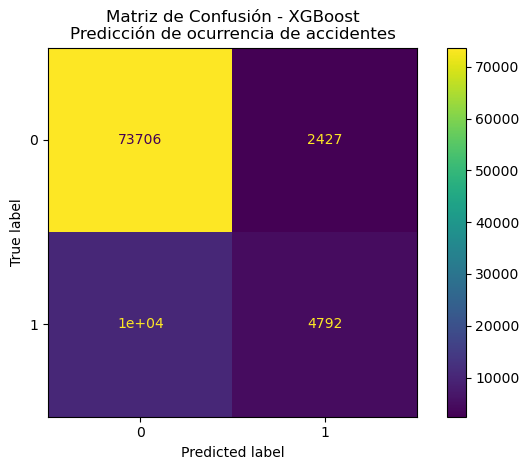

In [53]:
# Matriz de Confusion 

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_xgb
)

plt.title('Matriz de Confusión - XGBoost\nPredicción de ocurrencia de accidentes')
plt.tight_layout()

plt.savefig(
    'matriz_confusion_xgboost_ocurrencia.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

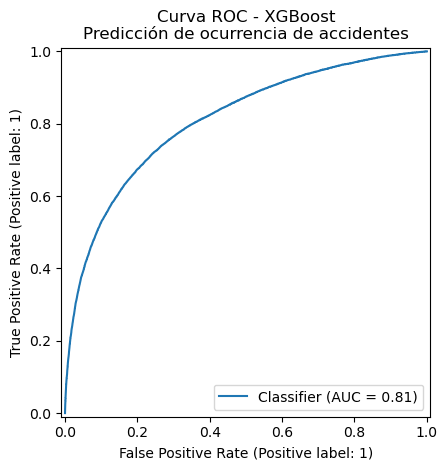

In [54]:
# Curva ROC

from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_xgb
)

plt.title('Curva ROC - XGBoost\nPredicción de ocurrencia de accidentes')
plt.tight_layout()

plt.savefig(
    'roc_xgboost_ocurrencia.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [55]:
# Calcular el peso de la clase positiva

negativos = (y_train == 0).sum()
positivos = (y_train == 1).sum()

scale_pos_weight = negativos / positivos

print("Negativos:", negativos)
print("Positivos:", positivos)
print("scale_pos_weight:", scale_pos_weight)

Negativos: 304527
Positivos: 60906
scale_pos_weight: 4.999950743769086


In [56]:
# Modelo Balanceado [XGBOOST BALANCEADO]

from xgboost import XGBClassifier

modelo_xgb_balanceado = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1
)

modelo_xgb_balanceado.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [57]:
y_pred_xgb_bal = modelo_xgb_balanceado.predict(X_test)

y_prob_xgb_bal = modelo_xgb_balanceado.predict_proba(X_test)[:, 1]

In [59]:
print("Accuracy:", accuracy_score(y_test, y_pred_xgb_bal))
print("Precision:", precision_score(y_test, y_pred_xgb_bal))
print("Recall:", recall_score(y_test, y_pred_xgb_bal))
print("F1-score:", f1_score(y_test, y_pred_xgb_bal))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_xgb_bal))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb_bal))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred_xgb_bal))

Accuracy: 0.7620705130310096
Precision: 0.3829420013663658
Recall: 0.6994614475239721
F1-score: 0.4949229732555708
ROC-AUC: 0.809275872831372

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.77      0.84     76133
           1       0.38      0.70      0.49     15226

    accuracy                           0.76     91359
   macro avg       0.66      0.74      0.67     91359
weighted avg       0.84      0.76      0.79     91359


Matriz de confusión:
[[58972 17161]
 [ 4576 10650]]


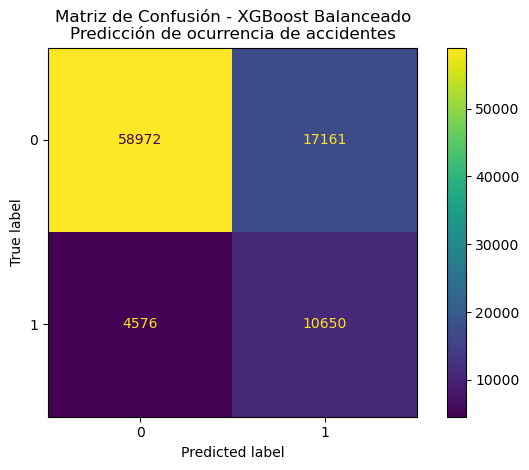

In [60]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_xgb_bal
)

plt.title(
    'Matriz de Confusión - XGBoost Balanceado\n'
    'Predicción de ocurrencia de accidentes'
)

plt.tight_layout()

plt.savefig(
    'matriz_confusion_xgboost_balanceado.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

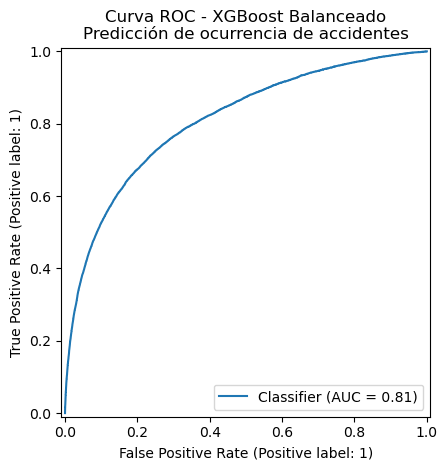

In [61]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_xgb_bal
)

plt.title(
    'Curva ROC - XGBoost Balanceado\n'
    'Predicción de ocurrencia de accidentes'
)

plt.tight_layout()

plt.savefig(
    'roc_xgboost_balanceado.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [62]:
import pandas as pd

comparacion_xgb = pd.DataFrame({
    'Modelo': [
        'XGBoost Base',
        'XGBoost Balanceado'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_xgb),
        accuracy_score(y_test, y_pred_xgb_bal)
    ],

    'Precision': [
        precision_score(y_test, y_pred_xgb),
        precision_score(y_test, y_pred_xgb_bal)
    ],

    'Recall': [
        recall_score(y_test, y_pred_xgb),
        recall_score(y_test, y_pred_xgb_bal)
    ],

    'F1-score': [
        f1_score(y_test, y_pred_xgb),
        f1_score(y_test, y_pred_xgb_bal)
    ],

    'ROC-AUC': [
        roc_auc_score(y_test, y_prob_xgb),
        roc_auc_score(y_test, y_prob_xgb_bal)
    ]
})

comparacion_xgb

,Modelo,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,XGBoost Base,0.859226,0.663804,0.314725,0.426999,0.809578
1,XGBoost Balanceado,0.762071,0.382942,0.699461,0.494923,0.809276


In [63]:
# Recuperar las características originales de los casos del conjunto de prueba
detalle_predicciones = dataset_base.loc[X_test.index, [
    'inverse_data',
    'hour',
    'state',
    'km_entero',
    'week_day',
    'road_direction',
    'road_type',
    'road_delineation'
]].copy()

# Agregar valor real
detalle_predicciones['real'] = y_test.values

# Agregar predicción del XGBoost balanceado
detalle_predicciones['prediccion'] = y_pred_xgb_bal

# Agregar probabilidad estimada por el modelo
detalle_predicciones['score_modelo'] = y_prob_xgb_bal

detalle_predicciones.head()

,inverse_data,hour,state,km_entero,week_day,road_direction,road_type,road_delineation,real,prediccion,score_modelo
152616,2017-01-27,19,ES,126,Friday,Increasing,Simple,Straight,0,1,0.696029
102225,2022-09-24,3,BA,744,Saturday,Increasing,Simple,Curve,0,0,0.207591
107393,2023-05-08,23,ES,445,Monday,Increasing,Simple,Straight,0,0,0.090568
63772,2020-01-07,6,BA,124,Tuesday,Increasing,Simple,Straight,0,0,0.250828
131604,2018-10-15,19,SC,212,Monday,Decreasing,Multiple,Straight,1,1,0.952382


In [64]:
detalle_predicciones.head(20)

,inverse_data,hour,state,km_entero,week_day,road_direction,road_type,road_delineation,real,prediccion,score_modelo
152616,2017-01-27,19,ES,126,Friday,Increasing,Simple,Straight,0,1,0.696029
102225,2022-09-24,3,BA,744,Saturday,Increasing,Simple,Curve,0,0,0.207591
107393,2023-05-08,23,ES,445,Monday,Increasing,Simple,Straight,0,0,0.090568
63772,2020-01-07,6,BA,124,Tuesday,Increasing,Simple,Straight,0,0,0.250828
131604,2018-10-15,19,SC,212,Monday,Decreasing,Multiple,Straight,1,1,0.952382
289480,2017-11-19,5,SC,442,Sunday,Increasing,Double,Straight,0,0,0.474526
447355,2018-01-09,9,RJ,485,Tuesday,Increasing,Simple,Straight,1,1,0.682404
456339,2023-04-08,13,BA,766,Saturday,Increasing,Simple,Straight,0,0,0.136286
411883,2017-03-16,3,ES,20,Thursday,Increasing,Simple,Straight,0,0,0.118811
435389,2019-05-01,13,RJ,140,Wednesday,Increasing,Double,Straight,0,0,0.239625


In [65]:
import numpy as np

condiciones = [
    (detalle_predicciones['real'] == 1) & (detalle_predicciones['prediccion'] == 1),
    (detalle_predicciones['real'] == 0) & (detalle_predicciones['prediccion'] == 0),
    (detalle_predicciones['real'] == 0) & (detalle_predicciones['prediccion'] == 1),
    (detalle_predicciones['real'] == 1) & (detalle_predicciones['prediccion'] == 0)
]

categorias = [
    'Accidente detectado',
    'No accidente detectado',
    'Falsa alarma',
    'Accidente no detectado'
]

detalle_predicciones['resultado'] = np.select(
    condiciones,
    categorias,
    default='Otro'
)

detalle_predicciones.head()

,inverse_data,hour,state,km_entero,week_day,road_direction,road_type,road_delineation,real,prediccion,score_modelo,resultado
152616,2017-01-27,19,ES,126,Friday,Increasing,Simple,Straight,0,1,0.696029,Falsa alarma
102225,2022-09-24,3,BA,744,Saturday,Increasing,Simple,Curve,0,0,0.207591,No accidente detectado
107393,2023-05-08,23,ES,445,Monday,Increasing,Simple,Straight,0,0,0.090568,No accidente detectado
63772,2020-01-07,6,BA,124,Tuesday,Increasing,Simple,Straight,0,0,0.250828,No accidente detectado
131604,2018-10-15,19,SC,212,Monday,Decreasing,Multiple,Straight,1,1,0.952382,Accidente detectado


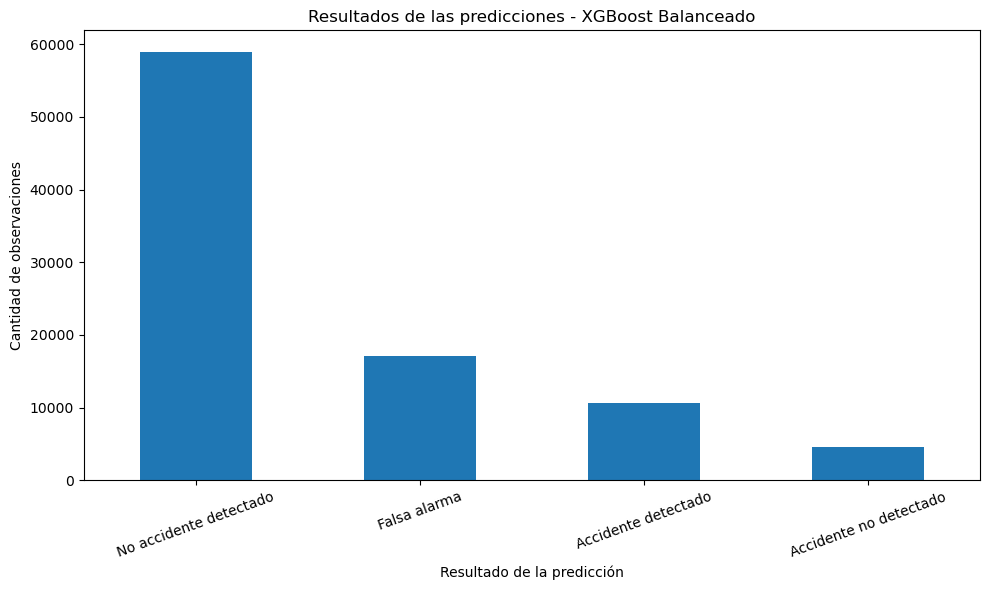

In [66]:
import matplotlib.pyplot as plt

conteo_resultados = detalle_predicciones['resultado'].value_counts()

plt.figure(figsize=(10, 6))

conteo_resultados.plot(kind='bar')

plt.title('Resultados de las predicciones - XGBoost Balanceado')
plt.xlabel('Resultado de la predicción')
plt.ylabel('Cantidad de observaciones')

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [67]:
# Accidentes Detectados 

accidentes_detectados = detalle_predicciones[
    (detalle_predicciones['real'] == 1) &
    (detalle_predicciones['prediccion'] == 1)
]

accidentes_detectados.head(20)

,inverse_data,hour,state,km_entero,week_day,road_direction,road_type,road_delineation,real,prediccion,score_modelo,resultado
131604,2018-10-15,19,SC,212,Monday,Decreasing,Multiple,Straight,1,1,0.952382,Accidente detectado
447355,2018-01-09,9,RJ,485,Tuesday,Increasing,Simple,Straight,1,1,0.682404,Accidente detectado
195924,2023-04-10,1,SC,193,Monday,Decreasing,Double,Straight,1,1,0.729087,Accidente detectado
309189,2020-01-16,15,SP,49,Thursday,Increasing,Simple,Straight,1,1,0.883306,Accidente detectado
177558,2019-10-22,16,SC,202,Tuesday,Increasing,Multiple,Straight,1,1,0.939904,Accidente detectado
1634,2023-08-17,7,SC,369,Thursday,Increasing,Double,Straight,1,1,0.577025,Accidente detectado
7425,2020-05-10,16,RN,79,Sunday,Decreasing,Double,Straight,1,1,0.747058,Accidente detectado
396315,2020-01-30,0,ES,293,Thursday,Decreasing,Double,Straight,1,1,0.560118,Accidente detectado
210258,2017-12-06,7,SC,208,Wednesday,Decreasing,Multiple,Straight,1,1,0.969385,Accidente detectado
443733,2021-02-27,18,RJ,482,Saturday,Decreasing,Simple,Straight,1,1,0.602605,Accidente detectado


In [68]:
accidentes_detectados['week_day'].value_counts()

week_day
Saturday     1848
Sunday       1721
Friday       1699
Monday       1521
Thursday     1339
Wednesday    1272
Tuesday      1250
Name: count, dtype: int64

In [69]:
accidentes_detectados['hour'].value_counts().sort_index()

hour
0     194
1     151
2     134
3     135
4     180
5     215
6     451
7     713
8     608
9     486
10    446
11    539
12    443
13    453
14    500
15    566
16    636
17    749
18    950
19    715
20    462
21    396
22    306
23    222
Name: count, dtype: int64

In [70]:
accidentes_detectados['state'].value_counts()

state
SC    4952
ES    1745
RJ    1478
PE    1164
RN     545
PB     292
SP     176
SE     155
BA      89
AL      33
RS      21
Name: count, dtype: int64

In [71]:
accidentes_detectados['road_delineation'].value_counts()


road_delineation
Straight             10012
Curve                  464
Not Reported           112
Intersection            51
Roundabout               8
Authorized U-turn        3
Name: count, dtype: int64

In [72]:
accidentes_detectados['road_type'].value_counts()

road_type
Double      7320
Multiple    1856
Simple      1474
Name: count, dtype: int64

In [73]:
accidentes_detectados['km_entero'].value_counts().head(20)

km_entero
206    126
210     99
213     97
208     96
203     95
269     89
214     85
211     85
204     83
83      78
270     78
50      77
207     76
209     75
215     75
68      74
201     72
205     72
266     72
95      72
Name: count, dtype: int64

In [74]:
# Accidentes No detectados

accidentes_no_detectados = detalle_predicciones[
    (detalle_predicciones['real'] == 1) &
    (detalle_predicciones['prediccion'] == 0)
]

accidentes_no_detectados.head(20)

,inverse_data,hour,state,km_entero,week_day,road_direction,road_type,road_delineation,real,prediccion,score_modelo,resultado
200547,2017-12-14,18,RJ,554,Thursday,Increasing,Simple,Intersection,1,0,0.176030,Accidente no detectado
178542,2017-04-24,19,BA,100,Monday,Decreasing,Simple,Straight,1,0,0.278251,Accidente no detectado
32711,2019-01-01,2,SP,39,Tuesday,Decreasing,Simple,Straight,1,0,0.190157,Accidente no detectado
21445,2022-10-14,7,BA,38,Friday,Decreasing,Simple,Straight,1,0,0.145027,Accidente no detectado
204910,2021-03-07,13,ES,324,Sunday,Decreasing,Double,Straight,1,0,0.468085,Accidente no detectado
114406,2019-03-01,12,PE,136,Friday,Decreasing,Double,Curve,1,0,0.331349,Accidente no detectado
233022,2018-08-17,10,BA,421,Friday,Increasing,Simple,Curve,1,0,0.371419,Accidente no detectado
355584,2018-01-23,9,AL,39,Tuesday,Decreasing,Double,Curve,1,0,0.303629,Accidente no detectado
384868,2021-06-04,15,BA,488,Friday,Increasing,Simple,Curve,1,0,0.267692,Accidente no detectado
370043,2020-09-13,22,BA,323,Sunday,Decreasing,Simple,Straight,1,0,0.224266,Accidente no detectado


In [75]:
accidentes_no_detectados['hour'].value_counts().sort_index()

hour
0     143
1     155
2     143
3     149
4     154
5     209
6     200
7     206
8     200
9     197
10    220
11    219
12    194
13    203
14    222
15    216
16    218
17    200
18    197
19    202
20    209
21    190
22    159
23    171
Name: count, dtype: int64

In [76]:
accidentes_no_detectados['state'].value_counts()

state
BA    1134
ES     777
RJ     747
SC     415
AL     341
SE     309
PE     260
PB     220
RS     183
RN     145
SP      45
Name: count, dtype: int64

In [77]:
accidentes_no_detectados['week_day'].value_counts()

week_day
Thursday     686
Sunday       685
Friday       677
Monday       661
Saturday     658
Tuesday      630
Wednesday    579
Name: count, dtype: int64

In [78]:
accidentes_no_detectados['road_delineation'].value_counts()

road_delineation
Straight             3069
Curve                1197
Not Reported          257
Intersection           26
Temporary Detour       10
Roundabout              9
Bridge                  4
Authorized U-turn       4
Name: count, dtype: int64

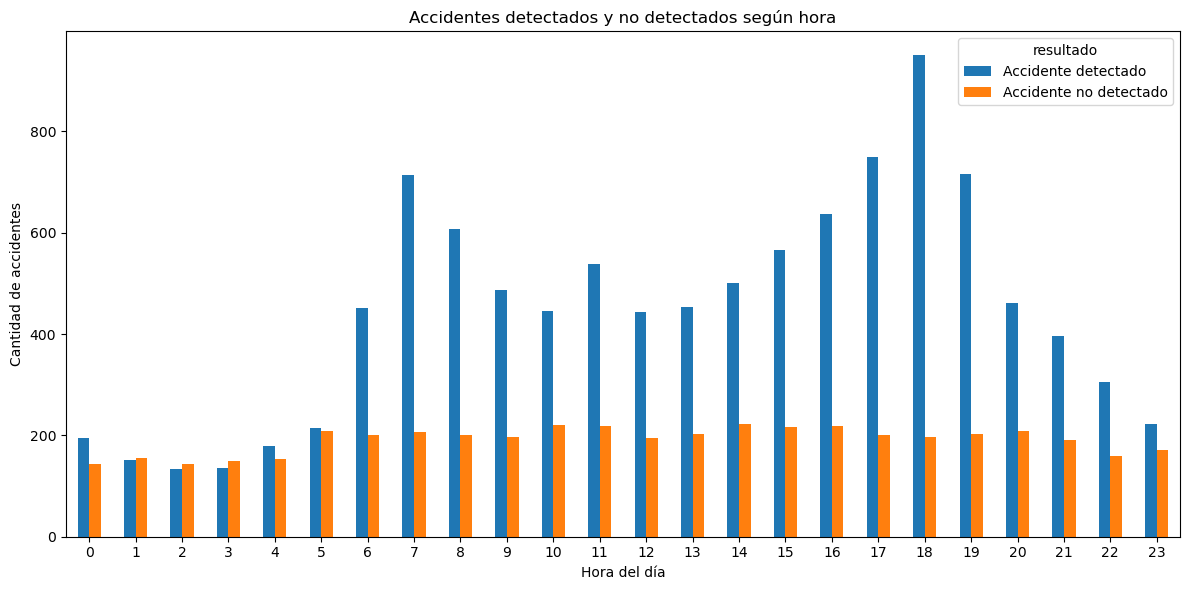

In [79]:
comparacion_hora = (
    detalle_predicciones[
        detalle_predicciones['real'] == 1
    ]
    .groupby(['hour', 'resultado'])
    .size()
    .unstack(fill_value=0)
)

comparacion_hora[
    ['Accidente detectado', 'Accidente no detectado']
].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Accidentes detectados y no detectados según hora')
plt.xlabel('Hora del día')
plt.ylabel('Cantidad de accidentes')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

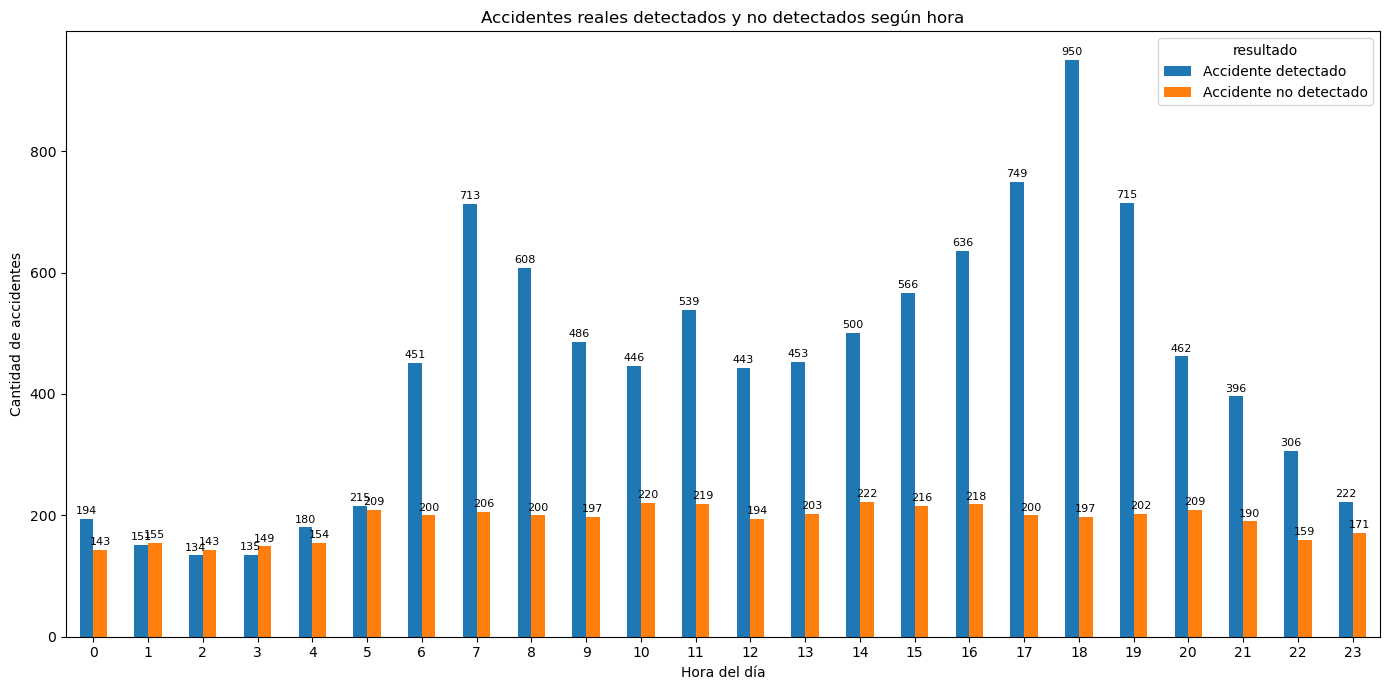

In [80]:
# Accidentes reales según hora
comparacion_hora = (
    detalle_predicciones[
        detalle_predicciones['real'] == 1
    ]
    .groupby(['hour', 'resultado'])
    .size()
    .unstack(fill_value=0)
)

ax = comparacion_hora[
    ['Accidente detectado', 'Accidente no detectado']
].plot(
    kind='bar',
    figsize=(14, 7)
)

plt.title('Accidentes reales detectados y no detectados según hora')
plt.xlabel('Hora del día')
plt.ylabel('Cantidad de accidentes')
plt.xticks(rotation=0)

# Mostrar cantidad exacta sobre cada barra
for container in ax.containers:
    ax.bar_label(container, fontsize=8, padding=2)

plt.tight_layout()
plt.show()

In [81]:
detalle_predicciones['year'] = detalle_predicciones['inverse_data'].dt.year

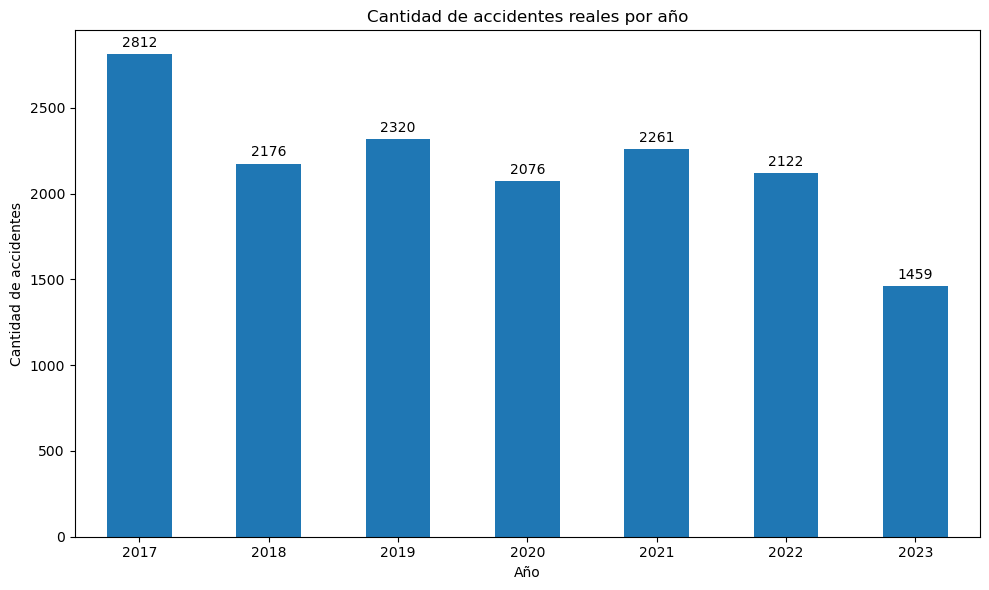

In [82]:
accidentes_por_anio = (
    detalle_predicciones[
        detalle_predicciones['real'] == 1
    ]
    ['year']
    .value_counts()
    .sort_index()
)

ax = accidentes_por_anio.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Cantidad de accidentes reales por año')
plt.xlabel('Año')
plt.ylabel('Cantidad de accidentes')
plt.xticks(rotation=0)

ax.bar_label(ax.containers[0], padding=3)

plt.tight_layout()
plt.show()

In [83]:
# SHAP

import shap
import matplotlib.pyplot as plt

In [84]:
explainer_xgb = shap.TreeExplainer(modelo_xgb_balanceado)

In [85]:
X_test_shap = X_test.sample(
    n=10000,
    random_state=42
)

shap_values_xgb = explainer_xgb(X_test_shap)

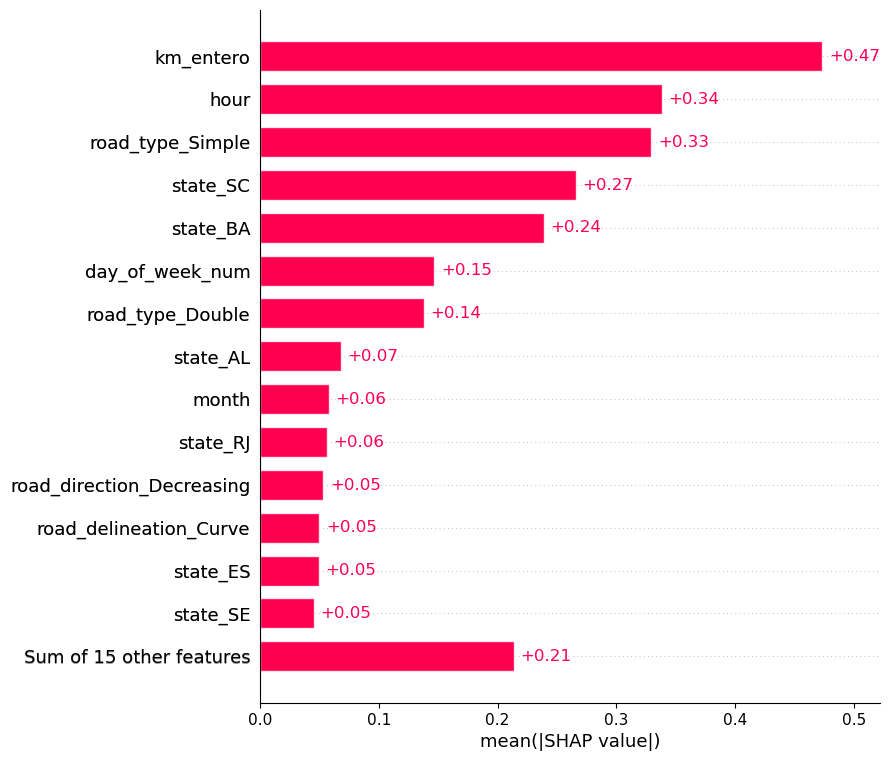

In [86]:
shap.plots.bar(
    shap_values_xgb,
    max_display=15
)

plt.show()

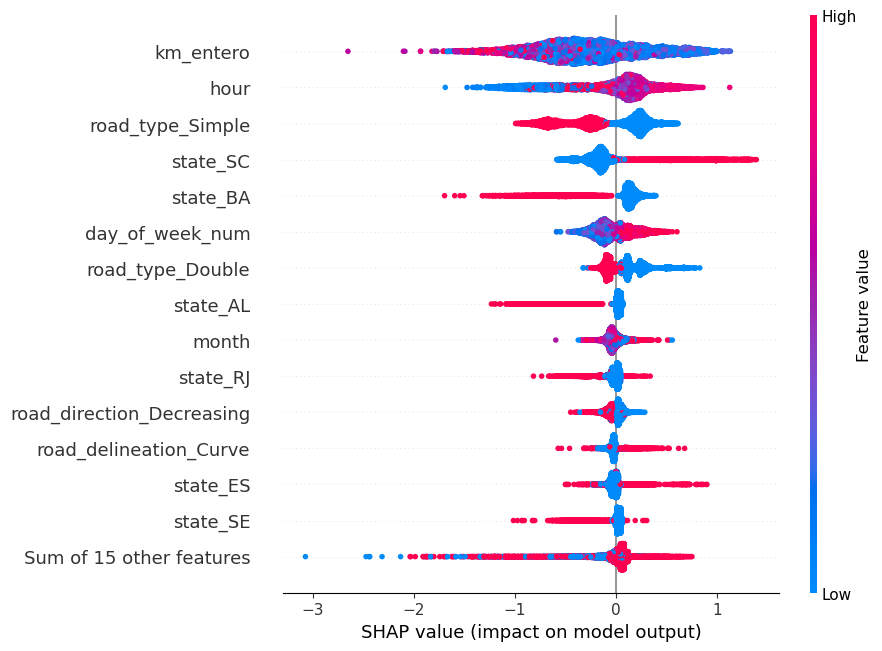

In [87]:
shap.plots.beeswarm(
    shap_values_xgb,
    max_display=15
)

plt.show()

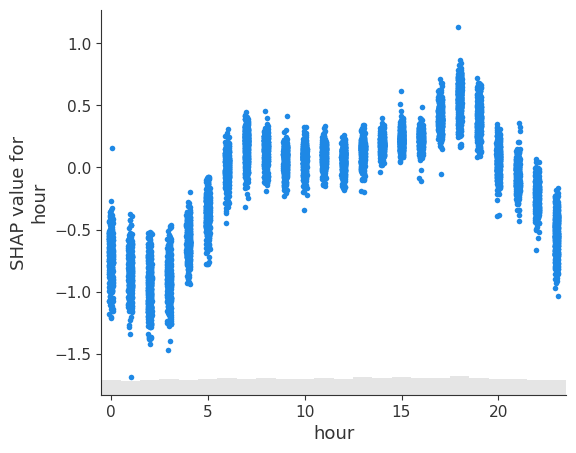

In [88]:
# SHAP para la hora

shap.plots.scatter(
    shap_values_xgb[:, 'hour']
)

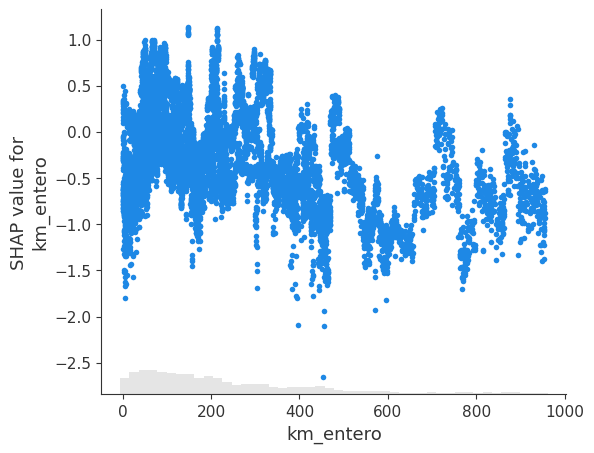

In [89]:
# SHAP KM
shap.plots.scatter(
    shap_values_xgb[:, 'km_entero']
)

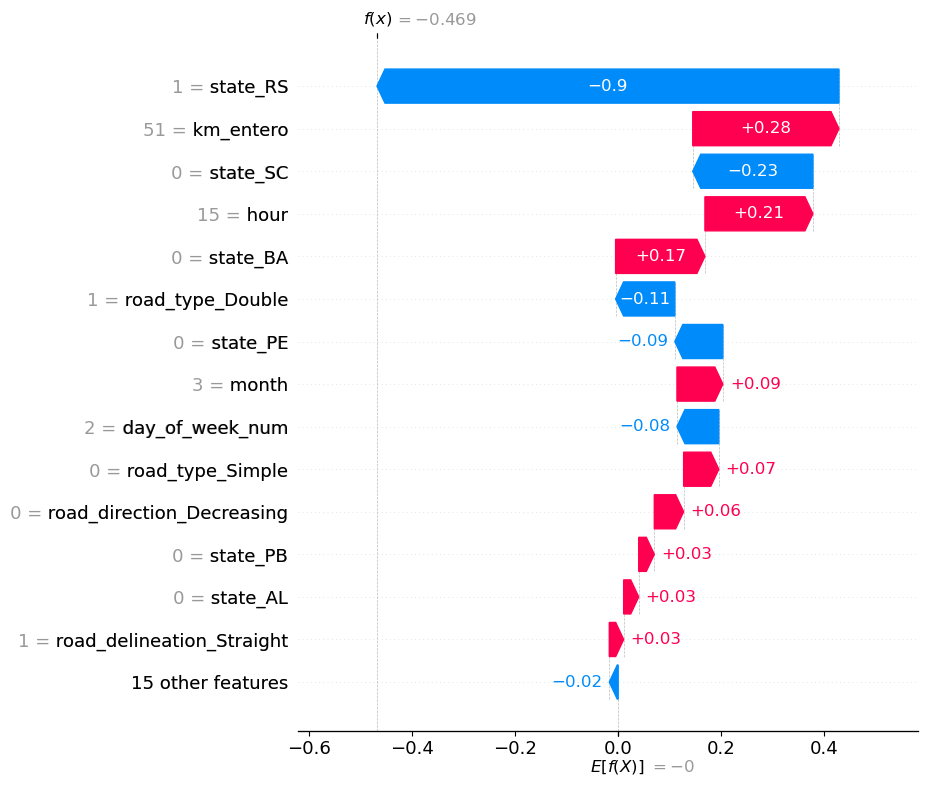

In [90]:
# Explicacion de una prediccion concreta

shap.plots.waterfall(
    shap_values_xgb[0],
    max_display=15
)

In [91]:
pred_shap = modelo_xgb_balanceado.predict(X_test_shap)

In [92]:
y_shap = y_test.loc[X_test_shap.index]

posiciones_correctas = (
    (y_shap.values == 1) &
    (pred_shap == 1)
)

indice_posicion = posiciones_correctas.nonzero()[0][0]

print("Posición:", indice_posicion)
print("Índice original:", X_test_shap.index[indice_posicion])

Posición: 7
Índice original: 344939


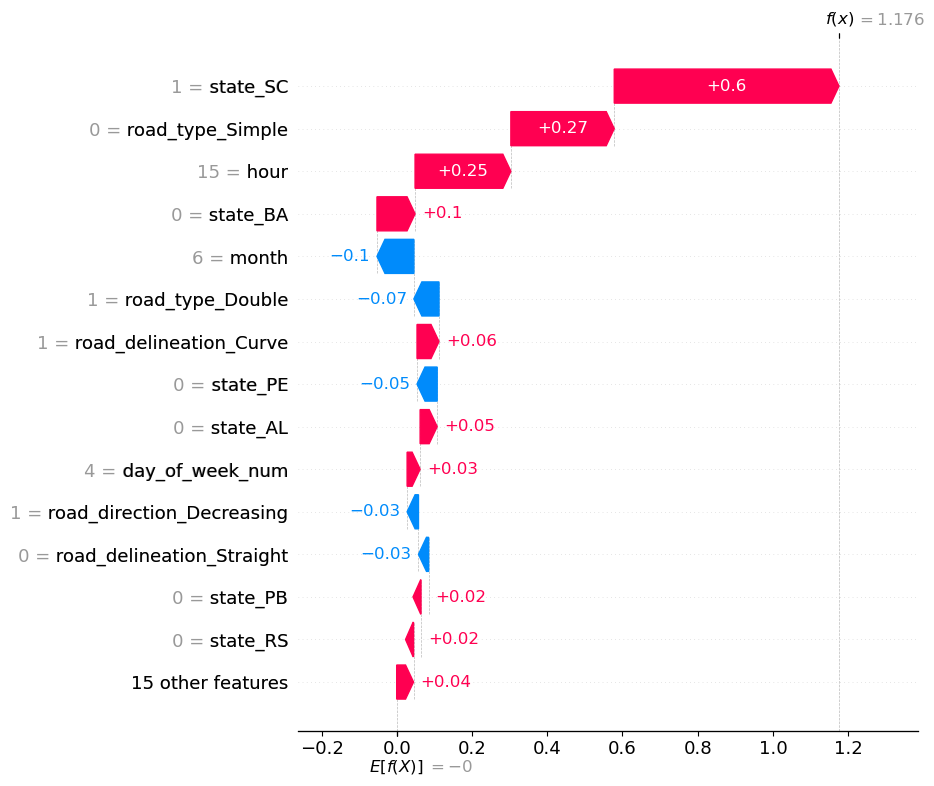

In [93]:
shap.plots.waterfall(
    shap_values_xgb[indice_posicion],
    max_display=15
)

In [94]:
indice_original = X_test_shap.index[indice_posicion]

dataset_base.loc[
    indice_original,
    [
        'inverse_data',
        'hour',
        'state',
        'km_entero',
        'week_day',
        'road_direction',
        'road_type',
        'road_delineation',
        'accident'
    ]
]

inverse_data        2020-06-05 00:00:00
hour                                 15
state                                SC
km_entero                            57
week_day                         Friday
road_direction               Decreasing
road_type                        Double
road_delineation                  Curve
accident                              1
Name: 344939, dtype: object

In [95]:
# Modelo LightGBM

from lightgbm import LGBMClassifier

In [96]:
# Modelo LightGBM Base

modelo_lgbm_occ = LGBMClassifier(
    objective='binary',
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

modelo_lgbm_occ.fit(X_train, y_train)

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,6
,learning_rate,0.1
,n_estimators,300
,subsample_for_bin,200000
,objective,'binary'
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [97]:
# Predicciones

y_pred_lgbm = modelo_lgbm_occ.predict(X_test)

y_prob_lgbm = modelo_lgbm_occ.predict_proba(X_test)[:, 1]

In [98]:
# Evaluación LightGBM Base

print("Accuracy:", accuracy_score(y_test, y_pred_lgbm))
print("Precision:", precision_score(y_test, y_pred_lgbm))
print("Recall:", recall_score(y_test, y_pred_lgbm))
print("F1-score:", f1_score(y_test, y_pred_lgbm))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lgbm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lgbm))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred_lgbm))

Accuracy: 0.8588535338609223
Precision: 0.6675772825305536
Recall: 0.3049389202679627
F1-score: 0.41864658942338034
ROC-AUC: 0.8094134322296314

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.97      0.92     76133
           1       0.67      0.30      0.42     15226

    accuracy                           0.86     91359
   macro avg       0.77      0.64      0.67     91359
weighted avg       0.84      0.86      0.84     91359


Matriz de confusión:
[[73821  2312]
 [10583  4643]]


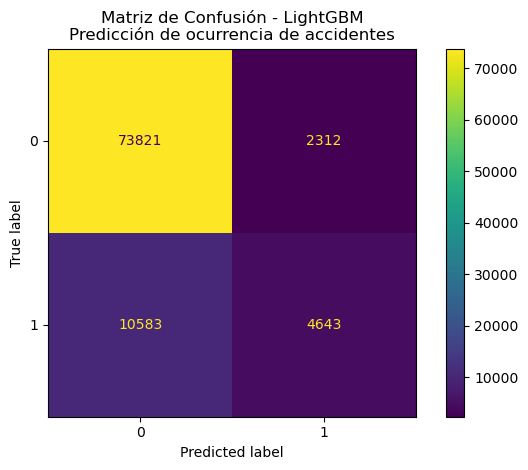

In [99]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lgbm
)

plt.title(
    'Matriz de Confusión - LightGBM\n'
    'Predicción de ocurrencia de accidentes'
)

plt.tight_layout()

plt.savefig(
    'matriz_confusion_lightgbm_ocurrencia.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

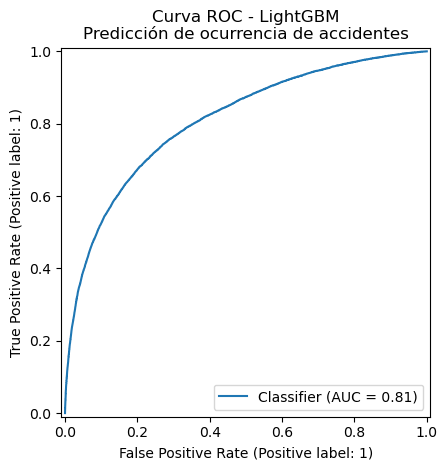

In [100]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_lgbm
)

plt.title(
    'Curva ROC - LightGBM\n'
    'Predicción de ocurrencia de accidentes'
)

plt.tight_layout()

plt.savefig(
    'roc_lightgbm_ocurrencia.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [101]:
# LightGBM Balanceado 

class_weight='balanced'

In [102]:
# Modelo LightGBM Balanceado

modelo_lgbm_balanceado = LGBMClassifier(
    objective='binary',
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

modelo_lgbm_balanceado.fit(X_train, y_train)

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,6
,learning_rate,0.1
,n_estimators,300
,subsample_for_bin,200000
,objective,'binary'
,class_weight,'balanced'
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [103]:
y_pred_lgbm_bal = modelo_lgbm_balanceado.predict(X_test)

y_prob_lgbm_bal = modelo_lgbm_balanceado.predict_proba(X_test)[:, 1]

In [104]:
print("Accuracy:", accuracy_score(y_test, y_pred_lgbm_bal))
print("Precision:", precision_score(y_test, y_pred_lgbm_bal))
print("Recall:", recall_score(y_test, y_pred_lgbm_bal))
print("F1-score:", f1_score(y_test, y_pred_lgbm_bal))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lgbm_bal))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lgbm_bal))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred_lgbm_bal))

Accuracy: 0.7600236429908384
Precision: 0.38082698740303184
Recall: 0.7028766583475634
F1-score: 0.4939992614475628
ROC-AUC: 0.8093586962547441

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.77      0.84     76133
           1       0.38      0.70      0.49     15226

    accuracy                           0.76     91359
   macro avg       0.65      0.74      0.67     91359
weighted avg       0.84      0.76      0.78     91359


Matriz de confusión:
[[58733 17400]
 [ 4524 10702]]


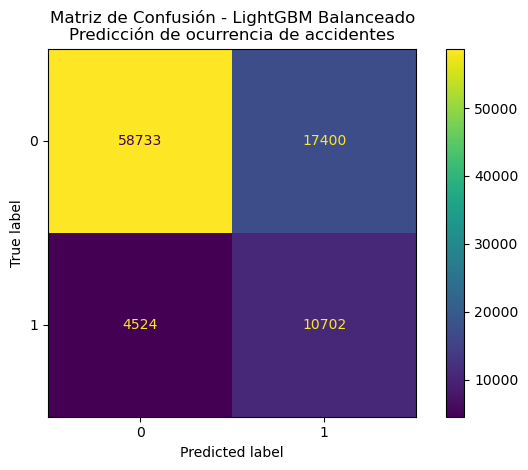

In [105]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lgbm_bal
)

plt.title(
    'Matriz de Confusión - LightGBM Balanceado\n'
    'Predicción de ocurrencia de accidentes'
)

plt.tight_layout()

plt.savefig(
    'matriz_confusion_lightgbm_balanceado.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

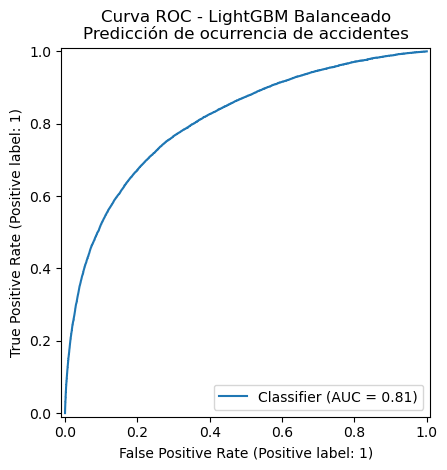

In [106]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_lgbm_bal
)

plt.title(
    'Curva ROC - LightGBM Balanceado\n'
    'Predicción de ocurrencia de accidentes'
)

plt.tight_layout()

plt.savefig(
    'roc_lightgbm_balanceado.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
# SHAP lightGBM Balanceado

In [107]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [108]:
# SHAP - LightGBM Balanceado para ocurrencia

# Muestra representativa del conjunto de prueba
X_test_shap_lgbm = X_test.sample(
    n=10000,
    random_state=42
)

print("Tamaño de la muestra SHAP:", X_test_shap_lgbm.shape)

Tamaño de la muestra SHAP: (10000, 29)


In [109]:
# Crear explicador SHAP para LightGBM balanceado
explainer_lgbm = shap.TreeExplainer(
    modelo_lgbm_balanceado
)

# Calcular valores SHAP
shap_values_lgbm = explainer_lgbm(
    X_test_shap_lgbm
)

print("Dimensiones de los valores SHAP:")
print(shap_values_lgbm.values.shape)

Dimensiones de los valores SHAP:
(10000, 29)


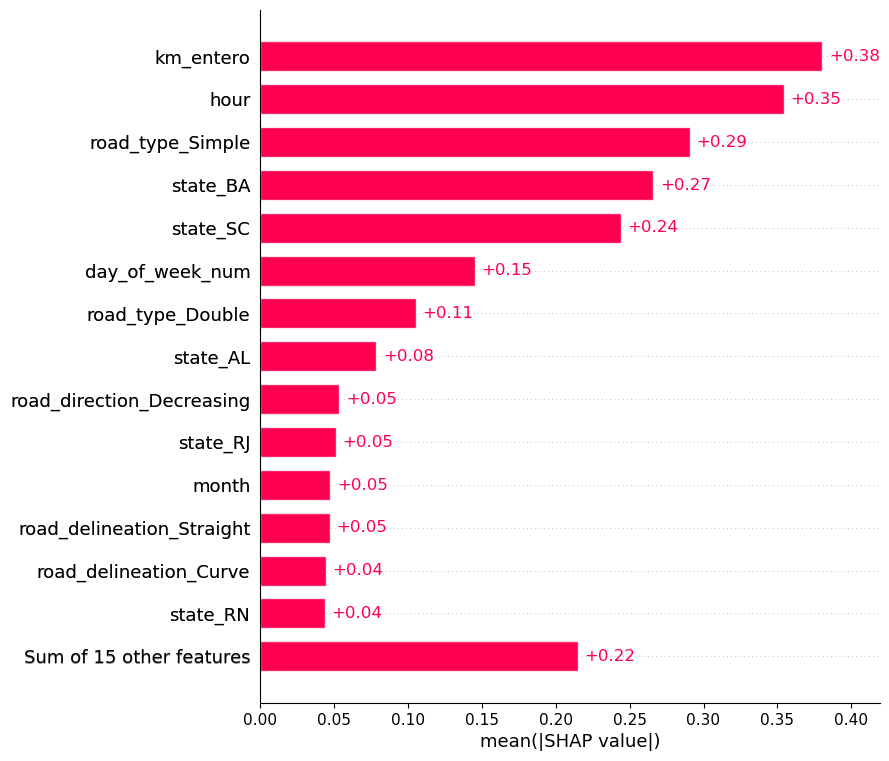

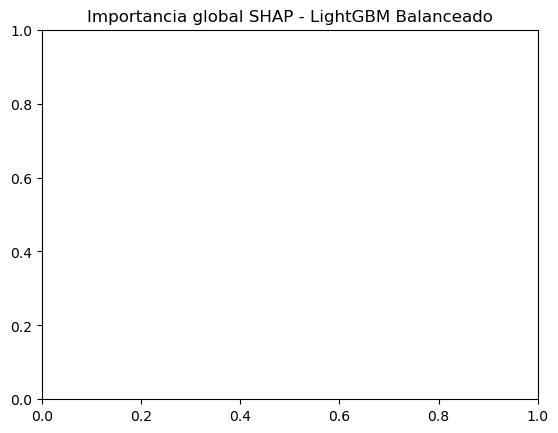

In [110]:
# Importancia global SHAP
shap.plots.bar(
    shap_values_lgbm,
    max_display=15
)

plt.title(
    'Importancia global SHAP - LightGBM Balanceado'
)

plt.show()

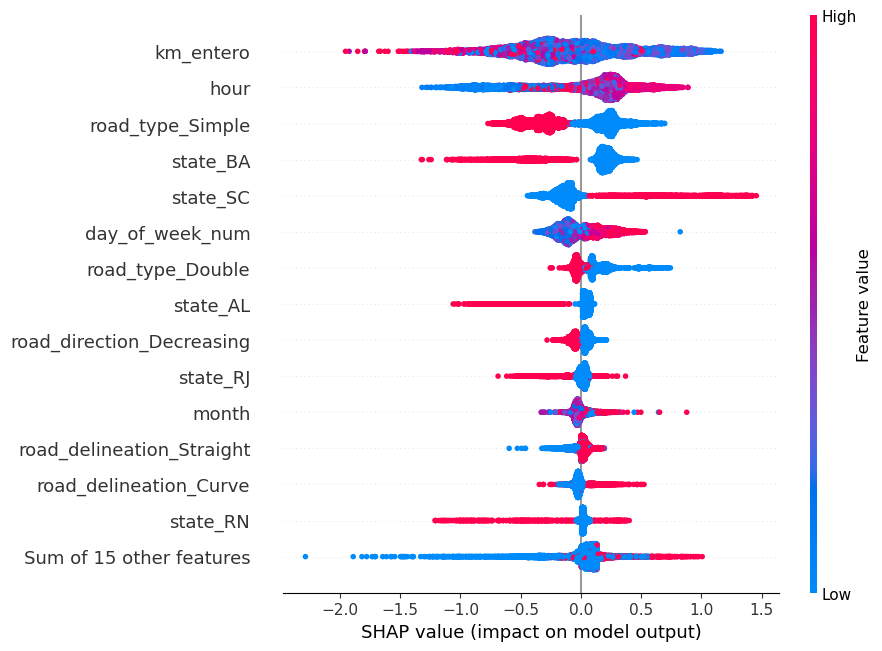

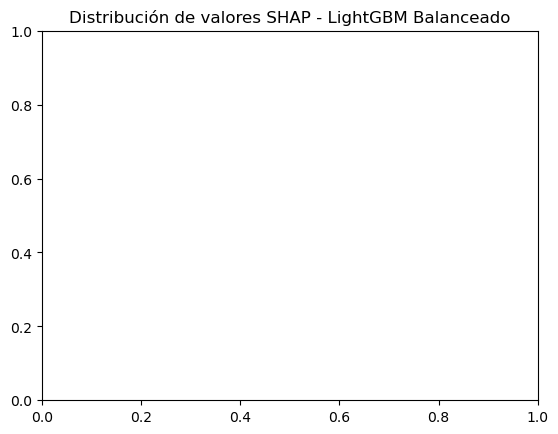

In [111]:
# Distribución e influencia de las variables
shap.plots.beeswarm(
    shap_values_lgbm,
    max_display=15
)

plt.title(
    'Distribución de valores SHAP - LightGBM Balanceado'
)

plt.show()

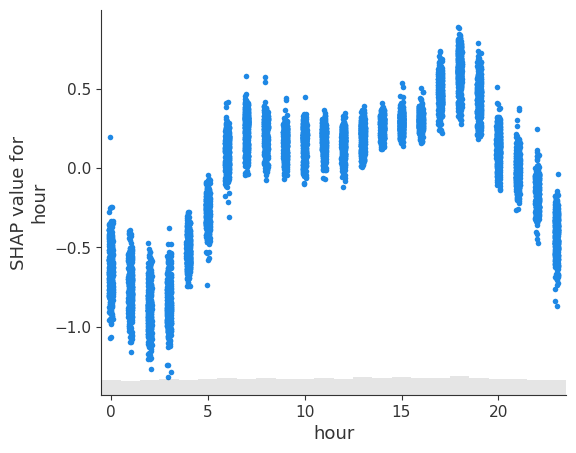

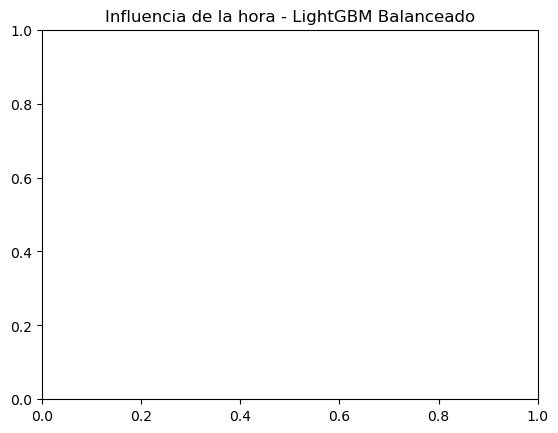

In [112]:
# Dependencia SHAP de la hora
shap.plots.scatter(
    shap_values_lgbm[:, 'hour']
)

plt.title(
    'Influencia de la hora - LightGBM Balanceado'
)

plt.show()

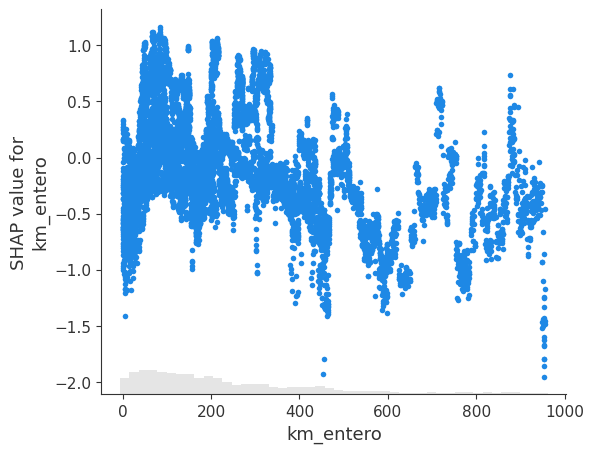

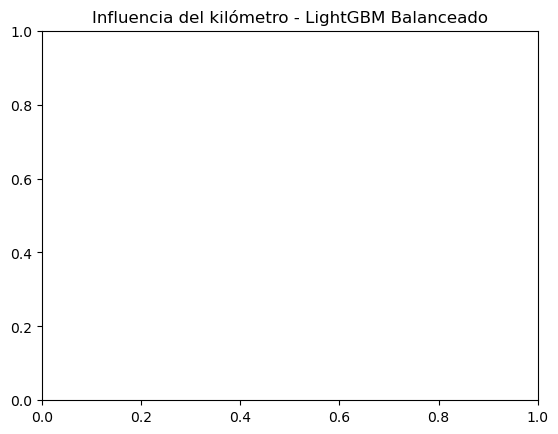

In [113]:
# Dependencia SHAP del kilómetro
shap.plots.scatter(
    shap_values_lgbm[:, 'km_entero']
)

plt.title(
    'Influencia del kilómetro - LightGBM Balanceado'
)

plt.show()

In [114]:
# Predicciones sobre la muestra utilizada para SHAP
pred_shap_lgbm = modelo_lgbm_balanceado.predict(
    X_test_shap_lgbm
)

# Obtener clases reales correspondientes
y_shap_lgbm = y_test.loc[
    X_test_shap_lgbm.index
]

# Buscar accidentes correctamente detectados
posiciones_correctas_lgbm = (
    (y_shap_lgbm.values == 1) &
    (pred_shap_lgbm == 1)
)

# Seleccionar el primer accidente correctamente detectado
indice_posicion_lgbm = np.where(
    posiciones_correctas_lgbm
)[0][0]

print(
    "Posición dentro de la muestra SHAP:",
    indice_posicion_lgbm
)

print(
    "Índice original del registro:",
    X_test_shap_lgbm.index[indice_posicion_lgbm]
)

Posición dentro de la muestra SHAP: 1
Índice original del registro: 75650


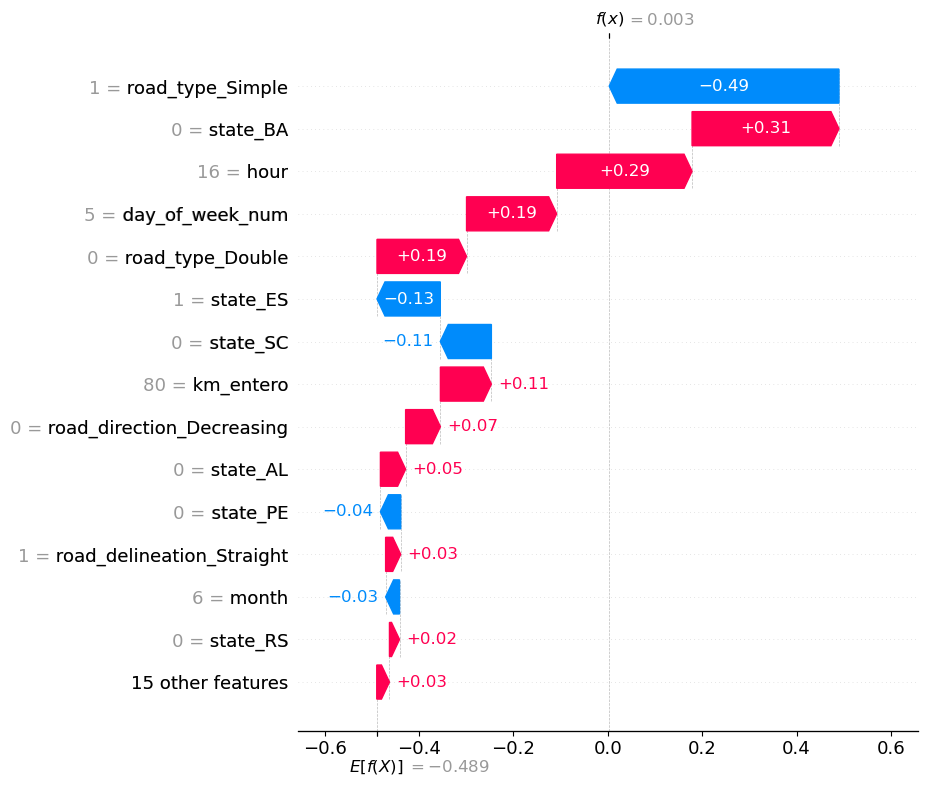

In [115]:
# Explicación individual de una predicción correcta
shap.plots.waterfall(
    shap_values_lgbm[indice_posicion_lgbm],
    max_display=15
)

plt.show()

In [116]:
# Recuperar índice original
indice_original_lgbm = (
    X_test_shap_lgbm.index[indice_posicion_lgbm]
)

# Mostrar información original del accidente
dataset_base.loc[
    indice_original_lgbm,
    [
        'inverse_data',
        'hour',
        'state',
        'km_entero',
        'week_day',
        'road_direction',
        'road_type',
        'road_delineation',
        'accident'
    ]
]

inverse_data        2022-06-04 00:00:00
hour                                 16
state                                ES
km_entero                            80
week_day                       Saturday
road_direction               Increasing
road_type                        Simple
road_delineation               Straight
accident                              1
Name: 75650, dtype: object

In [117]:
# Calcular importancia media absoluta SHAP
importancia_lgbm = np.abs(
    shap_values_lgbm.values
).mean(axis=0)

# Crear tabla de importancia
tabla_importancia_lgbm = pd.DataFrame({
    'Variable': X_test_shap_lgbm.columns,
    'Importancia_SHAP': importancia_lgbm
})

# Ordenar de mayor a menor importancia
tabla_importancia_lgbm = (
    tabla_importancia_lgbm
    .sort_values(
        'Importancia_SHAP',
        ascending=False
    )
    .reset_index(drop=True)
)

tabla_importancia_lgbm.head(15)

,Variable,Importancia_SHAP
0,km_entero,0.380329
1,hour,0.354142
2,road_type_Simple,0.290751
3,state_BA,0.266098
4,state_SC,0.244102
5,day_of_week_num,0.145227
6,road_type_Double,0.105210
7,state_AL,0.078773
8,road_direction_Decreasing,0.053651
9,state_RJ,0.051159


In [118]:
# Importancia media absoluta SHAP de XGBoost
importancia_xgb = np.abs(
    shap_values_xgb.values
).mean(axis=0)

# Importancia media absoluta SHAP de LightGBM
importancia_lgbm = np.abs(
    shap_values_lgbm.values
).mean(axis=0)

# Crear tabla comparativa
comparacion_shap = pd.DataFrame({
    'Variable': X_test_shap_lgbm.columns,
    'XGBoost': importancia_xgb,
    'LightGBM': importancia_lgbm
})

# Calcular importancia promedio entre ambos modelos
comparacion_shap['Promedio'] = (
    comparacion_shap['XGBoost'] +
    comparacion_shap['LightGBM']
) / 2

# Ordenar
comparacion_shap = (
    comparacion_shap
    .sort_values(
        'Promedio',
        ascending=False
    )
    .reset_index(drop=True)
)

comparacion_shap.head(15)

,Variable,XGBoost,LightGBM,Promedio
0,km_entero,0.473440,0.380329,0.426885
1,hour,0.338547,0.354142,0.346344
2,road_type_Simple,0.329580,0.290751,0.310165
3,state_SC,0.265961,0.244102,0.255031
4,state_BA,0.238772,0.266098,0.252435
5,day_of_week_num,0.146848,0.145227,0.146038
6,road_type_Double,0.137716,0.105210,0.121463
7,state_AL,0.068264,0.078773,0.073519
8,state_RJ,0.056299,0.051159,0.053729
9,road_direction_Decreasing,0.053353,0.053651,0.053502


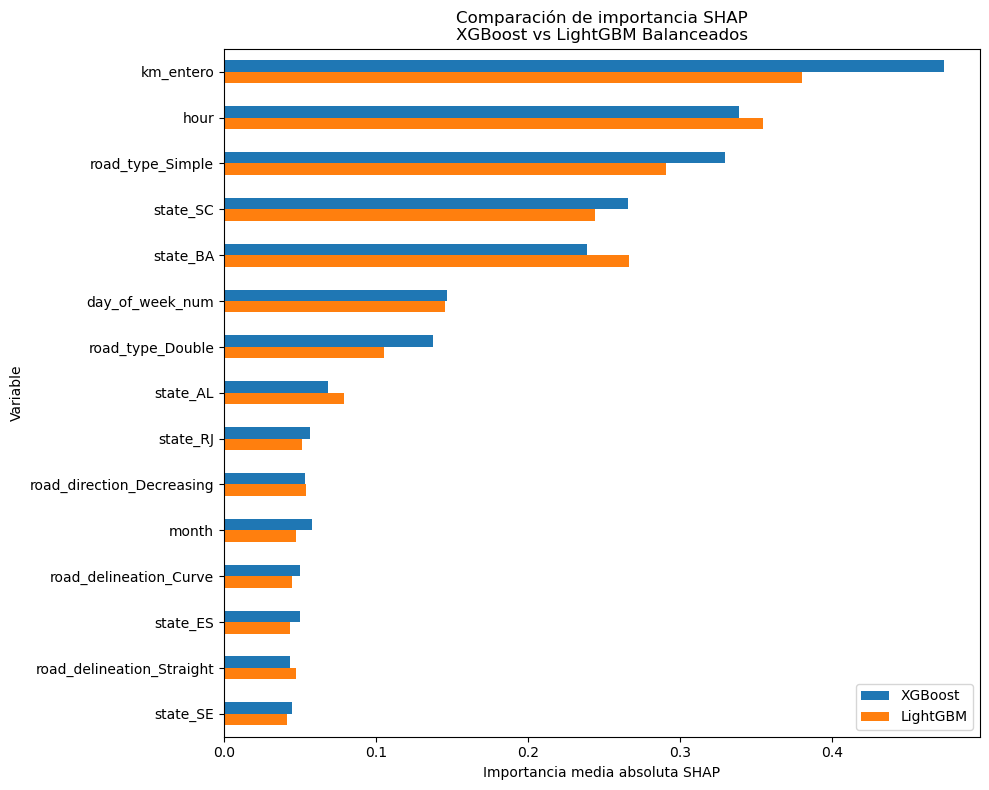

In [119]:
# Seleccionar las 15 variables más importantes
top_shap = comparacion_shap.head(15).copy()

# Preparar datos para gráfico
top_shap_plot = (
    top_shap
    .set_index('Variable')[
        ['XGBoost', 'LightGBM']
    ]
)

# Crear gráfico
top_shap_plot.plot(
    kind='barh',
    figsize=(10, 8)
)

plt.xlabel(
    'Importancia media absoluta SHAP'
)

plt.ylabel(
    'Variable'
)

plt.title(
    'Comparación de importancia SHAP\n'
    'XGBoost vs LightGBM Balanceados'
)

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [120]:
comparacion_modelos = pd.DataFrame({
    'Modelo': [
        'XGBoost Base',
        'XGBoost Balanceado',
        'LightGBM Base',
        'LightGBM Balanceado'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_xgb),
        accuracy_score(y_test, y_pred_xgb_bal),
        accuracy_score(y_test, y_pred_lgbm),
        accuracy_score(y_test, y_pred_lgbm_bal)
    ],

    'Precision': [
        precision_score(y_test, y_pred_xgb),
        precision_score(y_test, y_pred_xgb_bal),
        precision_score(y_test, y_pred_lgbm),
        precision_score(y_test, y_pred_lgbm_bal)
    ],

    'Recall': [
        recall_score(y_test, y_pred_xgb),
        recall_score(y_test, y_pred_xgb_bal),
        recall_score(y_test, y_pred_lgbm),
        recall_score(y_test, y_pred_lgbm_bal)
    ],

    'F1-score': [
        f1_score(y_test, y_pred_xgb),
        f1_score(y_test, y_pred_xgb_bal),
        f1_score(y_test, y_pred_lgbm),
        f1_score(y_test, y_pred_lgbm_bal)
    ],

    'ROC-AUC': [
        roc_auc_score(y_test, y_prob_xgb),
        roc_auc_score(y_test, y_prob_xgb_bal),
        roc_auc_score(y_test, y_prob_lgbm),
        roc_auc_score(y_test, y_prob_lgbm_bal)
    ]
})

comparacion_modelos

,Modelo,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,XGBoost Base,0.859226,0.663804,0.314725,0.426999,0.809578
1,XGBoost Balanceado,0.762071,0.382942,0.699461,0.494923,0.809276
2,LightGBM Base,0.858854,0.667577,0.304939,0.418647,0.809413
3,LightGBM Balanceado,0.760024,0.380827,0.702877,0.493999,0.809359


In [ ]:
# EXPERIMENTO CARRETERA BR-116

In [121]:
test_size=0.20
random_state=42

In [122]:
n_estimators=300
max_depth=6
learning_rate=0.1

In [123]:
# Seleccionar únicamente los registros de la BR-116
df_occ_116 = df[df['road_id'] == 116].copy()

print(df_occ_116.shape)

(68814, 27)


##  SIMULACIONES

# XGBOOST

In [124]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

import pandas as pd
import numpy as np

In [125]:
# Funcion para evaluar todos los experimentos

def evaluar_modelo_ocurrencia(nombre, modelo, X_test, y_test):

    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)

    matriz = confusion_matrix(y_test, y_pred)

    print("=" * 60)
    print(nombre)
    print("=" * 60)

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-score : {f1:.4f}")
    print(f"ROC-AUC  : {roc_auc:.4f}")
    print(f"PR-AUC   : {pr_auc:.4f}")

    print("\nMatriz de confusión:")
    print(matriz)

    return {
        'Experimento': nombre,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1': f1,
        'ROC_AUC': roc_auc,
        'PR_AUC': pr_auc,
        'TN': matriz[0, 0],
        'FP': matriz[0, 1],
        'FN': matriz[1, 0],
        'TP': matriz[1, 1]
    }

In [126]:
# XGB-O1 — Modelo base

resultado_xgb_o1 = evaluar_modelo_ocurrencia(
    'XGB-O1 - Base',
    modelo_xgb_occ,
    X_test,
    y_test
)


XGB-O1 - Base
Accuracy : 0.8592
Precision: 0.6638
Recall   : 0.3147
F1-score : 0.4270
ROC-AUC  : 0.8096
PR-AUC   : 0.5286

Matriz de confusión:
[[73706  2427]
 [10434  4792]]


In [127]:
# XGB-O2 — Balanceado

resultado_xgb_o2 = evaluar_modelo_ocurrencia(
    'XGB-O2 - Balanceado',
    modelo_xgb_balanceado,
    X_test,
    y_test
)


XGB-O2 - Balanceado
Accuracy : 0.7621
Precision: 0.3829
Recall   : 0.6995
F1-score : 0.4949
ROC-AUC  : 0.8093
PR-AUC   : 0.5269

Matriz de confusión:
[[58972 17161]
 [ 4576 10650]]


In [128]:
# XGB-O3 — Balanceado + regularización [NUEVO EXPERIMENTO]

modelo_xgb_o3 = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',

    n_estimators=300,
    max_depth=4,
    learning_rate=0.1,

    scale_pos_weight=scale_pos_weight,

    subsample=0.8,
    colsample_bytree=0.8,

    reg_lambda=1.0,
    reg_alpha=0.1,

    random_state=42,
    n_jobs=-1
)

modelo_xgb_o3.fit(
    X_train,
    y_train
)

resultado_xgb_o3 = evaluar_modelo_ocurrencia(
    'XGB-O3 - Balanceado y regularizado',
    modelo_xgb_o3,
    X_test,
    y_test
)


XGB-O3 - Balanceado y regularizado
Accuracy : 0.7472
Precision: 0.3664
Recall   : 0.7087
F1-score : 0.4830
ROC-AUC  : 0.8031
PR-AUC   : 0.5118

Matriz de confusión:
[[57473 18660]
 [ 4436 10790]]


In [129]:
# XGB-O4 — Configuración refinada

modelo_xgb_o4 = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',

    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,

    scale_pos_weight=scale_pos_weight,

    subsample=0.8,
    colsample_bytree=0.8,

    min_child_weight=3,
    gamma=0.1,

    reg_lambda=1.0,
    reg_alpha=0.1,

    random_state=42,
    n_jobs=-1
)

modelo_xgb_o4.fit(
    X_train,
    y_train
)

resultado_xgb_o4 = evaluar_modelo_ocurrencia(
    'XGB-O4 - Configuración refinada',
    modelo_xgb_o4,
    X_test,
    y_test
)

XGB-O4 - Configuración refinada
Accuracy : 0.7537
Precision: 0.3737
Recall   : 0.7072
F1-score : 0.4890
ROC-AUC  : 0.8069
PR-AUC   : 0.5193

Matriz de confusión:
[[58088 18045]
 [ 4458 10768]]


## LIGHTGBM

In [130]:
# LGBM-O1 - Base
resultado_lgbm_o1 = evaluar_modelo_ocurrencia(
    'LGBM-O1 - Base',
    modelo_lgbm_occ,
    X_test,
    y_test
)

LGBM-O1 - Base
Accuracy : 0.8589
Precision: 0.6676
Recall   : 0.3049
F1-score : 0.4186
ROC-AUC  : 0.8094
PR-AUC   : 0.5269

Matriz de confusión:
[[73821  2312]
 [10583  4643]]


In [131]:
# LGBM-O2 — Balanceado
resultado_lgbm_o2 = evaluar_modelo_ocurrencia(
    'LGBM-O2 - Balanceado',
    modelo_lgbm_balanceado,
    X_test,
    y_test
)

LGBM-O2 - Balanceado
Accuracy : 0.7600
Precision: 0.3808
Recall   : 0.7029
F1-score : 0.4940
ROC-AUC  : 0.8094
PR-AUC   : 0.5249

Matriz de confusión:
[[58733 17400]
 [ 4524 10702]]


In [132]:
# LGBM-O3 — Balanceado + regularización [NUEVO EXPERIMENTO]

modelo_lgbm_o3 = LGBMClassifier(
    objective='binary',

    n_estimators=300,
    max_depth=4,
    learning_rate=0.1,

    class_weight='balanced',

    num_leaves=15,

    subsample=0.8,
    colsample_bytree=0.8,

    reg_lambda=1.0,
    reg_alpha=0.1,

    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

modelo_lgbm_o3.fit(
    X_train,
    y_train
)

resultado_lgbm_o3 = evaluar_modelo_ocurrencia(
    'LGBM-O3 - Balanceado y regularizado',
    modelo_lgbm_o3,
    X_test,
    y_test
)


LGBM-O3 - Balanceado y regularizado
Accuracy : 0.7488
Precision: 0.3680
Recall   : 0.7066
F1-score : 0.4839
ROC-AUC  : 0.8036
PR-AUC   : 0.5124

Matriz de confusión:
[[57654 18479]
 [ 4468 10758]]


In [133]:
# LGBM-O4 — Configuración refinada

modelo_lgbm_o4 = LGBMClassifier(
    objective='binary',

    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,

    class_weight='balanced',

    num_leaves=31,

    subsample=0.8,
    colsample_bytree=0.8,

    min_child_samples=30,

    reg_lambda=1.0,
    reg_alpha=0.1,

    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

modelo_lgbm_o4.fit(
    X_train,
    y_train
)

resultado_lgbm_o4 = evaluar_modelo_ocurrencia(
    'LGBM-O4 - Configuración refinada',
    modelo_lgbm_o4,
    X_test,
    y_test
)

LGBM-O4 - Configuración refinada
Accuracy : 0.7547
Precision: 0.3744
Recall   : 0.7033
F1-score : 0.4887
ROC-AUC  : 0.8067
PR-AUC   : 0.5194

Matriz de confusión:
[[58238 17895]
 [ 4517 10709]]


In [134]:
# COMPARACION DE LOS 8 EXPERIMENTOS

resultados_experimentos = pd.DataFrame([
    resultado_xgb_o1,
    resultado_xgb_o2,
    resultado_xgb_o3,
    resultado_xgb_o4,

    resultado_lgbm_o1,
    resultado_lgbm_o2,
    resultado_lgbm_o3,
    resultado_lgbm_o4
])

columnas_metricas = [
    'Experimento',
    'Accuracy',
    'Precision',
    'Recall',
    'F1',
    'ROC_AUC',
    'PR_AUC'
]

resultados_experimentos[columnas_metricas].round(4)

,Experimento,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,XGB-O1 - Base,0.8592,0.6638,0.3147,0.4270,0.8096,0.5286
1,XGB-O2 - Balanceado,0.7621,0.3829,0.6995,0.4949,0.8093,0.5269
2,XGB-O3 - Balanceado y regularizado,0.7472,0.3664,0.7087,0.4830,0.8031,0.5118
3,XGB-O4 - Configuración refinada,0.7537,0.3737,0.7072,0.4890,0.8069,0.5193
4,LGBM-O1 - Base,0.8589,0.6676,0.3049,0.4186,0.8094,0.5269
5,LGBM-O2 - Balanceado,0.7600,0.3808,0.7029,0.4940,0.8094,0.5249
6,LGBM-O3 - Balanceado y regularizado,0.7488,0.3680,0.7066,0.4839,0.8036,0.5124
7,LGBM-O4 - Configuración refinada,0.7547,0.3744,0.7033,0.4887,0.8067,0.5194


In [135]:
# Matrices de Confusion juntas

resultados_matrices = resultados_experimentos[
    [
        'Experimento',
        'TN',
        'FP',
        'FN',
        'TP'
    ]
]

resultados_matrices

,Experimento,TN,FP,FN,TP
0,XGB-O1 - Base,73706,2427,10434,4792
1,XGB-O2 - Balanceado,58972,17161,4576,10650
2,XGB-O3 - Balanceado y regularizado,57473,18660,4436,10790
3,XGB-O4 - Configuración refinada,58088,18045,4458,10768
4,LGBM-O1 - Base,73821,2312,10583,4643
5,LGBM-O2 - Balanceado,58733,17400,4524,10702
6,LGBM-O3 - Balanceado y regularizado,57654,18479,4468,10758
7,LGBM-O4 - Configuración refinada,58238,17895,4517,10709


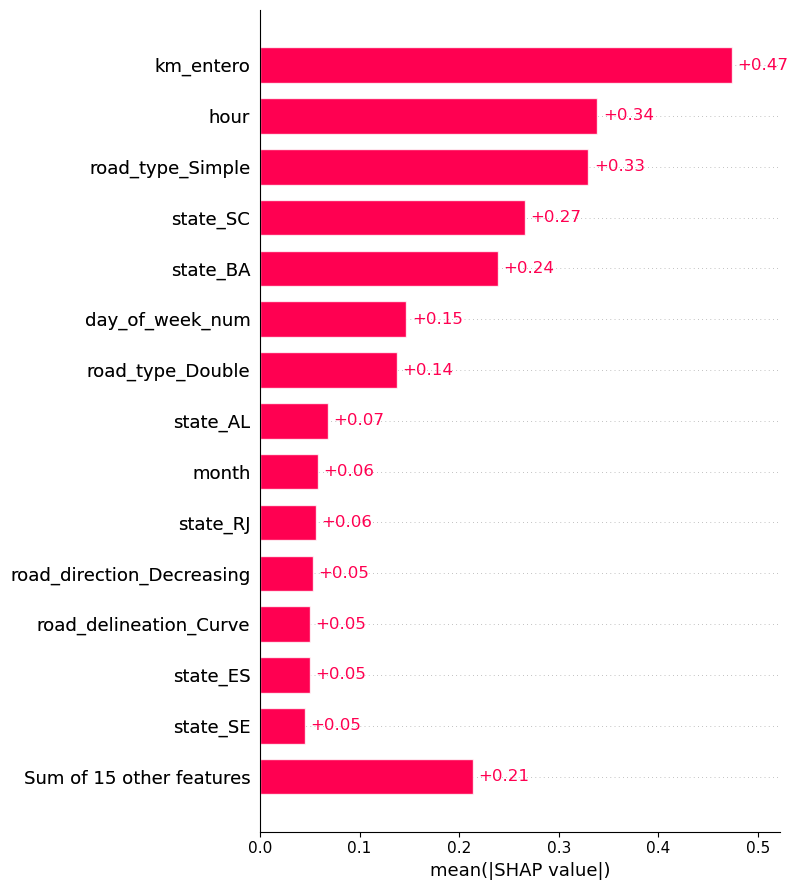

In [136]:
# 1. Importancia global
shap.plots.bar(
    shap_values_xgb,
    max_display=15,
    show=False
)
plt.tight_layout()
plt.savefig(
    "Figura_SHAP_XGBoost_importancia_global.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

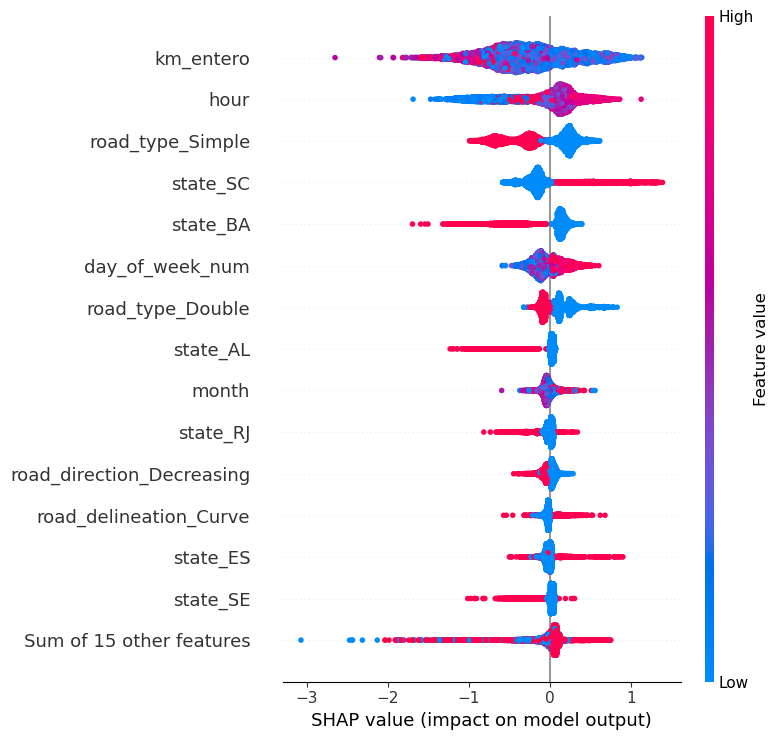

In [137]:
# 2. Beeswarm
shap.plots.beeswarm(
    shap_values_xgb,
    max_display=15,
    show=False
)
plt.tight_layout()
plt.savefig(
    "Figura_SHAP_XGBoost_beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

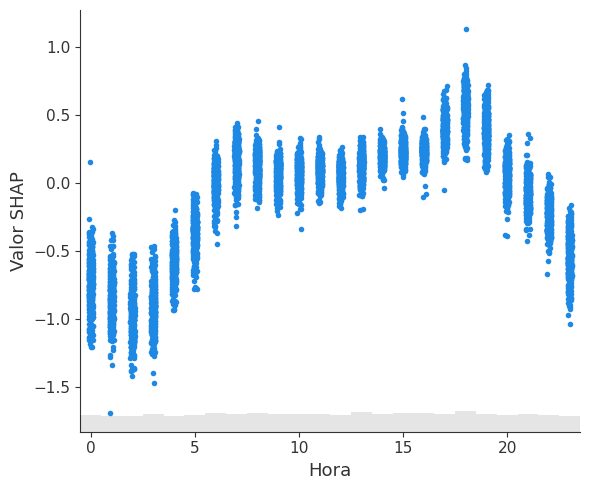

In [138]:
# 3. Influencia de la hora
shap.plots.scatter(
    shap_values_xgb[:, "hour"],
    show=False
)
plt.xlabel("Hora")
plt.ylabel("Valor SHAP")
plt.tight_layout()
plt.savefig(
    "Figura_SHAP_XGBoost_hora.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

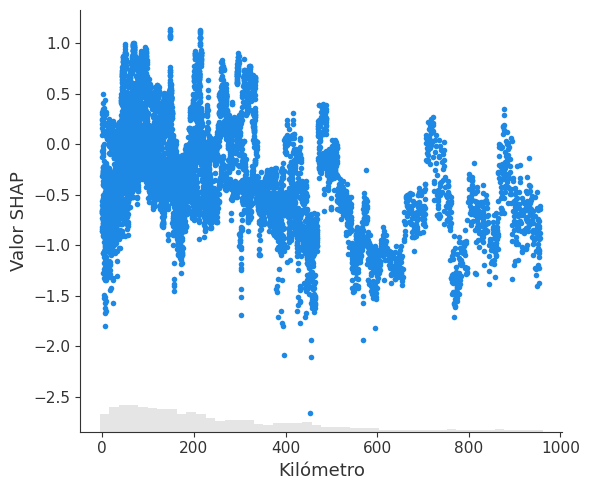

In [139]:
# 4. Influencia del kilómetro
shap.plots.scatter(
    shap_values_xgb[:, "km_entero"],
    show=False
)
plt.xlabel("Kilómetro")
plt.ylabel("Valor SHAP")
plt.tight_layout()
plt.savefig(
    "Figura_SHAP_XGBoost_kilometro.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

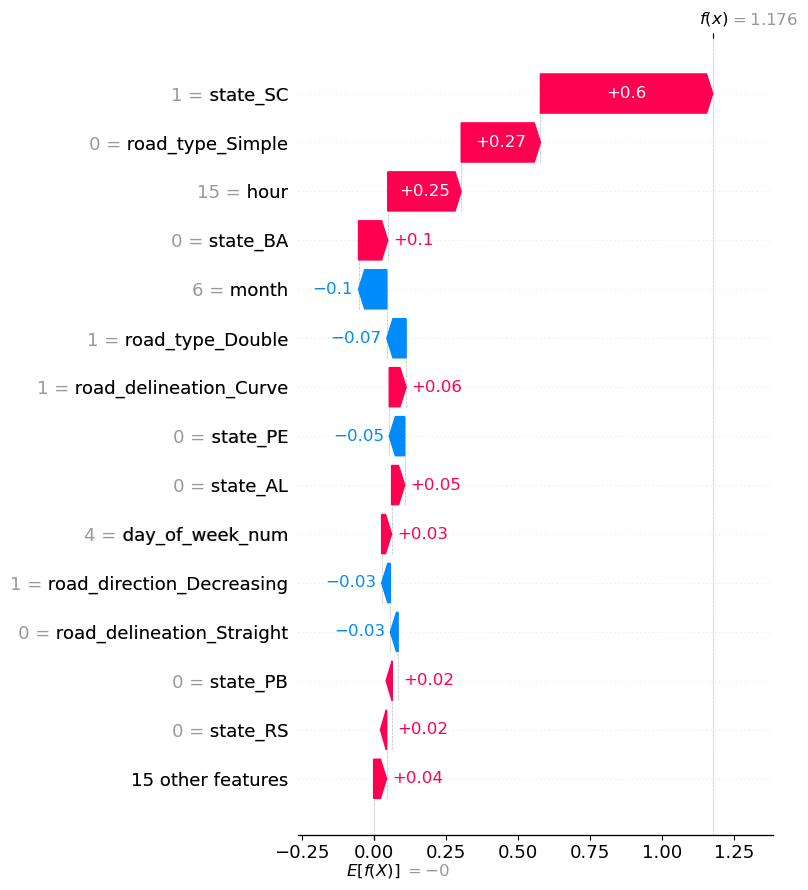

In [140]:
# 5. Explicación individual
shap.plots.waterfall(
    shap_values_xgb[indice_posicion],
    max_display=15,
    show=False
)

plt.tight_layout()
plt.savefig(
    "Figura_SHAP_XGBoost_waterfall.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [ ]:
import os
print(os.getcwd())